# Data 6 — MITMAPS Multi-tone MAPS Rheological Data: Master Analysis Pipeline
## Phases A through W | Two Files (Maps + SAOS) | Complete Analysis

**Dataset:** Multi-tone Medium Amplitude Parallel Superposition (MAPS) rheological data  
**Source:** github.com/krlennon/mitmaps | Lennon et al. 2020 | MIT Hydrodynamics Lab  
**Instrument:** TA Instruments Discovery HR-3 | Date: 3/6/2020  
**Material:** Viscoelastic fluid  
**Project:** Wavelet-Based Time-Frequency Analysis Pipeline — Haemograph Pty Ltd  

### Files
- **Data6_maps.xlsx** — 24 steps (Arbitrary Wave 1-24), each ~26,366 rows at 488, 244, 122, or 61 Hz
- **Data6_saos.xlsx** — 16 frequency points from 0.1 to 100 rad/s, G and G at 25 degrees C

### Columns in each MAPS step
Displacement [rad], Gap [um], Normal stress [Pa], Step time [s],  
Strain [%], Stress [Pa], Temperature [degrees C], Time [s], Torque [uN.m],  
Compliance [1/Pa], Strain (step) [%]

### Key Dataset Properties
- Raw stress and strain at 61 to 488 Hz — fully applicable to FFT, STFT, and CWT
- Multi-tone broadband excitation — designed for simultaneous harmonic extraction
- Non-gelling stationary material — best used for pipeline validation and algorithm benchmarking
- No gelation, no gel point, no mutation number analysis
- 24 steps at varying sampling rates and durations

### Why This Dataset Matters for the Pipeline
Data 6 is the dataset where Fourier SUCCEEDS — stationary, broadband, high sampling rate.  
Data 4 is where Fourier FAILS — non-stationary, low sampling rate, gelating material.  
Together they provide the full comparison needed to justify wavelet analysis.

## PHASE A — Data Integrity and Experimental Validation

In [1]:
# ==========================================
# CELL A1: All Imports
# ==========================================

import sys
!{sys.executable} -m pip install pandas numpy matplotlib scipy statsmodels openpyxl PyWavelets -q

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os
import warnings
from scipy import stats
from scipy.signal import butter, filtfilt, stft, windows as scipy_windows, find_peaks, welch
from scipy.stats import pearsonr, spearmanr
from scipy.fft import fft, fftfreq
from statsmodels.tsa.stattools import adfuller, kpss
import pywt
warnings.filterwarnings('ignore')

matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['font.size'] = 10

print("All imports successful.")
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("pywt:", pywt.__version__)

All imports successful.
numpy: 2.3.5
pandas: 2.3.3
pywt: 1.8.0


In [2]:
# ==========================================
# CELL A2: Load Data6_maps.xlsx — Summary and All 24 Steps
# ==========================================

MAPS_FILE_PATH = "Data6_maps.xlsx"
SAOS_FILE_PATH = "Data6_saos.xlsx"

MAPS_COLUMNS = [
    'displacement_rad',
    'gap_um',
    'normal_stress_Pa',
    'step_time_s',
    'strain_pct',
    'stress_Pa',
    'temperature_C',
    'time_s',
    'torque_uNm',
    'compliance_per_Pa',
    'strain_step_pct'
]

SAOS_COLUMNS = [
    'storage_modulus_Pa',
    'loss_modulus_Pa',
    'tan_delta',
    'angular_freq_rad_s',
    'oscillation_torque_uNm',
    'step_time_s',
    'temperature_C',
    'raw_phase_deg',
    'oscillation_displacement_rad',
    'complex_viscosity_Pa_s',
    'axial_force_N',
    'oscillation_stress_Pa',
    'time_s'
]

# Load summary sheet
maps_summary_df = pd.read_excel(MAPS_FILE_PATH, sheet_name='Summary', header=2)
maps_summary_df.columns = ['Sheet', 'Step_Name', 'Data_Rows', 'Sampling_Hz', 'Duration_s', 'Columns']
maps_summary_df = maps_summary_df.dropna(subset=['Sheet']).reset_index(drop=True)

print("=" * 70)
print("MAPS SUMMARY — 24 STEPS")
print("=" * 70)
print(maps_summary_df.to_string(index=False))

maps_steps_dictionary = {}
print("\nLoading 24 data steps (Step_2 to Step_25)...")

# Step_1 is instrument metadata — skip it
# Actual data is in Step_2 through Step_25
# Row 1 = title, Row 2 = column headers, Row 3 = units, Row 4+ = data
for step_number in range(2, 26):
    sheet_name      = f"Step_{step_number}"
    dict_key        = sheet_name
    try:
        step_df = pd.read_excel(
            MAPS_FILE_PATH,
            sheet_name=sheet_name,
            header=1,       # row 2 (0-indexed = 1) = column headers
            skiprows=[2]    # skip row 3 which is units
        )
        step_df = step_df.iloc[:, :len(MAPS_COLUMNS)]
        step_df.columns = MAPS_COLUMNS
        for column_name in step_df.columns:
            step_df[column_name] = pd.to_numeric(step_df[column_name], errors='coerce')
        step_df = step_df.dropna(subset=['stress_Pa']).reset_index(drop=True)
        maps_steps_dictionary[dict_key] = step_df
        print(f"  {sheet_name} -> {dict_key}: {len(step_df)} rows loaded")
    except Exception as error_message:
        print(f"  Error loading {sheet_name}: {error_message}")

print(f"\nTotal steps loaded: {len(maps_steps_dictionary)}")

MAPS SUMMARY — 24 STEPS
  Sheet           Step_Name  Data_Rows  Sampling_Hz  Duration_s  Columns
 Step_1   fFilename\tmaps_7         75          NaN         NaN        2
 Step_2  Arbitrary Wave - 1      26366        488.0     53.9955       11
 Step_3  Arbitrary Wave - 2      26366        244.0    107.9910       11
 Step_4  Arbitrary Wave - 3      26366        122.0    215.9820       11
 Step_5  Arbitrary Wave - 4      26366         61.0    431.9640       11
 Step_6  Arbitrary Wave - 5      26366        488.0     53.9955       11
 Step_7  Arbitrary Wave - 6      26366        244.0    107.9910       11
 Step_8  Arbitrary Wave - 7      26367        122.0    215.9900       11
 Step_9  Arbitrary Wave - 8      26366         61.0    431.9640       11
Step_10  Arbitrary Wave - 9      26366        488.0     53.9955       11
Step_11 Arbitrary Wave - 10      26366        244.0    107.9910       11
Step_12 Arbitrary Wave - 11      26367        122.0    215.9900       11
Step_13 Arbitrary Wave - 12

In [3]:
# ==========================================
# CELL A3: Load Data6_saos.xlsx
# ==========================================

saos_df = pd.read_excel(SAOS_FILE_PATH, sheet_name='SAOS Frequency Sweep', header=1, skiprows=[2])
saos_df = saos_df.iloc[:, :len(SAOS_COLUMNS)]
saos_df.columns = SAOS_COLUMNS
for column_name in saos_df.columns:
    saos_df[column_name] = pd.to_numeric(saos_df[column_name], errors='coerce')
saos_df = saos_df.dropna(subset=['angular_freq_rad_s']).reset_index(drop=True)

print("=" * 70)
print("SAOS FREQUENCY SWEEP DATA")
print("=" * 70)
print(f"Shape: {saos_df.shape}")
print(f"Frequency range: {saos_df['angular_freq_rad_s'].min():.3f} to {saos_df['angular_freq_rad_s'].max():.3f} rad/s")
print(f"Temperature: {saos_df['temperature_C'].mean():.1f} degrees C")
print()
print(saos_df[['angular_freq_rad_s','storage_modulus_Pa','loss_modulus_Pa','tan_delta','complex_viscosity_Pa_s']].to_string(index=False))

SAOS FREQUENCY SWEEP DATA
Shape: (16, 13)
Frequency range: 0.100 to 100.000 rad/s
Temperature: 25.0 degrees C

 angular_freq_rad_s  storage_modulus_Pa  loss_modulus_Pa  tan_delta  complex_viscosity_Pa_s
         100.000000           43.371400          3.88842   0.089654                0.435454
          63.095700           41.827200          3.64171   0.087065                0.665425
          39.810500           40.968500          3.75379   0.091626                1.033400
          25.118800           40.243700          4.24953   0.105595                1.611040
          15.849000           39.507800          5.33639   0.135072                2.515400
          10.000100           38.465600          7.14986   0.185877                3.912420
           6.309570           36.654500          9.94688   0.271369                6.019440
           3.981050           33.535700         13.37010   0.398683                9.068640
           2.511890           28.146900         16.84100   0.

In [4]:
# ==========================================
# CELL A4: Shape Validation and Sampling Rate Audit
# ==========================================

print("=" * 80)
print("SHAPE VALIDATION AND SAMPLING RATE AUDIT — ALL 24 STEPS")
print("=" * 80)
print(f"{'Step':>8} {'Step Name':>22} {'Rows':>8} {'Sampling (Hz)':>14} {'Duration (s)':>13} {'Cols':>6}")
print("-" * 80)

step_metadata_records = []

for step_number in range(2, 26):
    sheet_name = f"Step_{step_number}"
    if sheet_name not in maps_steps_dictionary:
        continue
    step_df        = maps_steps_dictionary[sheet_name]
    time_values    = step_df['step_time_s'].values
    delta_t_values = np.diff(time_values)
    positive_dts   = delta_t_values[delta_t_values > 0]
    mean_delta_t   = np.mean(positive_dts) if len(positive_dts) > 0 else 1
    sampling_rate_hz = round(1.0 / mean_delta_t) if mean_delta_t > 0 else 0
    duration_s       = time_values[-1] - time_values[0] if len(time_values) > 1 else 0
    summary_row      = maps_summary_df[maps_summary_df['Sheet'] == sheet_name]
    step_name        = summary_row['Step_Name'].values[0] if len(summary_row) > 0 else "Unknown"
    step_metadata_records.append({
        'Sheet': sheet_name,
        'Step_Name': step_name,
        'Rows': len(step_df),
        'Sampling_Hz': sampling_rate_hz,
        'Duration_s': round(duration_s, 2),
        'Columns': step_df.shape[1]
    })
    print(f"{sheet_name:>8} {str(step_name):>22} {len(step_df):>8} {sampling_rate_hz:>14} {duration_s:>13.2f} {step_df.shape[1]:>6}")

step_metadata_df = pd.DataFrame(step_metadata_records)

print("\nSampling rate distribution:")
for rate, count in step_metadata_df['Sampling_Hz'].value_counts().sort_index().items():
    print(f"  {rate} Hz: {count} steps")

SHAPE VALIDATION AND SAMPLING RATE AUDIT — ALL 24 STEPS
    Step              Step Name     Rows  Sampling (Hz)  Duration (s)   Cols
--------------------------------------------------------------------------------
  Step_2     Arbitrary Wave - 1    26366            488         54.00     11
  Step_3     Arbitrary Wave - 2    26366            244        107.99     11
  Step_4     Arbitrary Wave - 3    26366            122        215.98     11
  Step_5     Arbitrary Wave - 4    26366             61        431.96     11
  Step_6     Arbitrary Wave - 5    26366            488         54.00     11
  Step_7     Arbitrary Wave - 6    26366            244        107.99     11
  Step_8     Arbitrary Wave - 7    26367            122        215.99     11
  Step_9     Arbitrary Wave - 8    26366             61        431.96     11
 Step_10     Arbitrary Wave - 9    26366            488         54.00     11
 Step_11    Arbitrary Wave - 10    26366            244        107.99     11
 Step_12    Arbi

In [5]:
# ==========================================
# CELL A5: NaN Audit and Temperature Consistency
# ==========================================

print("=" * 60)
print("NaN AUDIT — ALL 24 STEPS")
print("=" * 60)

total_nan = 0
for step_number in range(2, 26):
    sheet_name = f"Step_{step_number}"
    if sheet_name not in maps_steps_dictionary:
        continue
    nan_count = maps_steps_dictionary[sheet_name].isnull().sum().sum()
    total_nan += nan_count
    if nan_count > 0:
        print(f"  {sheet_name}: {nan_count} NaN values")

if total_nan == 0:
    print("No NaN values found across all 24 steps.")

print("\n" + "=" * 70)
print("TEMPERATURE CONSISTENCY CHECK — SELECTED STEPS")
print("=" * 70)
print(f"{'Step':>8} {'Temp Mean (C)':>14} {'Temp Std':>10} {'Min':>8} {'Max':>8} {'Status':>10}")
print("-" * 60)
for step_number in range(2, 26, 6):
    sheet_name = f"Step_{step_number}"
    if sheet_name not in maps_steps_dictionary:
        continue
    temp_values = maps_steps_dictionary[sheet_name]['temperature_C'].values
    temp_ok = 23.0 < np.mean(temp_values) < 27.0
    print(f"{sheet_name:>8} {np.mean(temp_values):>14.2f} {np.std(temp_values):>10.4f} {np.min(temp_values):>8.2f} {np.max(temp_values):>8.2f} {'PASS' if temp_ok else 'CHECK':>10}")

NaN AUDIT — ALL 24 STEPS
No NaN values found across all 24 steps.

TEMPERATURE CONSISTENCY CHECK — SELECTED STEPS
    Step  Temp Mean (C)   Temp Std      Min      Max     Status
------------------------------------------------------------
  Step_2          25.00     0.0000    25.00    25.00       PASS
  Step_8          25.01     0.0000    25.01    25.01       PASS
 Step_14          25.00     0.0000    25.00    25.00       PASS
 Step_20          24.99     0.0000    25.00    25.00       PASS


## PHASE B — Advanced Signal Diagnostics

In [6]:
# ==========================================
# CELL B1: Stationarity Testing — ADF and KPSS
# ==========================================
# MAPS is a stationary material — we EXPECT stationary signals (ADF p < 0.05)
# This VALIDATES Fourier analysis for this dataset
# Contrast with Data 4 where ADF showed non-stationary G'(t) = Fourier fails

print("=" * 85)
print("STATIONARITY TESTING — STRESS SIGNAL, SELECTED STEPS")
print("=" * 85)
print("Expected: ADF p < 0.05 (stationary) — confirms LTI assumption is valid for MAPS data")
print()
print(f"{'Step':>8} {'Hz':>6} {'ADF p-value':>12} {'KPSS p-value':>13} {'Verdict':>16} {'LTI Valid':>10} {'FFT Valid':>10}")
print("-" * 85)

stationarity_records = []
steps_to_test = ['Step_2','Step_3','Step_4','Step_5','Step_6','Step_9','Step_13','Step_17','Step_21','Step_25']

for sheet_name in steps_to_test:
    if sheet_name not in maps_steps_dictionary:
        continue
    stress_signal    = maps_steps_dictionary[sheet_name]['stress_Pa'].values
    stress_subsample = stress_signal[::10]
    adf_result       = adfuller(stress_subsample, autolag='AIC')
    adf_p_value      = adf_result[1]
    try:
        kpss_result  = kpss(stress_subsample, regression='c', nlags='auto')
        kpss_p_value = kpss_result[1]
    except Exception:
        kpss_p_value = None
    verdict    = "Stationary" if adf_p_value < 0.05 else "Non-stationary"
    lti_valid  = "VALID" if adf_p_value < 0.05 else "VIOLATED"
    fft_valid  = "YES" if adf_p_value < 0.05 else "NO"
    kpss_str   = f"{kpss_p_value:.3f}" if kpss_p_value else "N/A"
    sampling_rate = step_metadata_df[step_metadata_df['Sheet'] == sheet_name]['Sampling_Hz'].values[0]
    stationarity_records.append({
        'Step': sheet_name, 'Sampling_Hz': sampling_rate,
        'ADF p': adf_p_value, 'Verdict': verdict, 'LTI Valid': lti_valid
    })
    print(f"{sheet_name:>8} {sampling_rate:>6} {adf_p_value:>12.4f} {kpss_str:>13} {verdict:>16} {lti_valid:>10} {fft_valid:>10}")

stationarity_df = pd.DataFrame(stationarity_records)
print("\nConclusion: MAPS signal is stationary — FFT is fully valid and appropriate.")
print("This contrasts with Data 4 (collagen gelation) where non-stationarity justified CWT.")

STATIONARITY TESTING — STRESS SIGNAL, SELECTED STEPS
Expected: ADF p < 0.05 (stationary) — confirms LTI assumption is valid for MAPS data

    Step     Hz  ADF p-value  KPSS p-value          Verdict  LTI Valid  FFT Valid
-------------------------------------------------------------------------------------
  Step_2    488       0.0000         0.100       Stationary      VALID        YES
  Step_3    244       0.0000         0.100       Stationary      VALID        YES
  Step_4    122       0.0000         0.100       Stationary      VALID        YES
  Step_5     61       0.0000         0.100       Stationary      VALID        YES
  Step_6    488       0.0000         0.100       Stationary      VALID        YES
  Step_9     61       0.0000         0.100       Stationary      VALID        YES
 Step_13     61       0.0000         0.100       Stationary      VALID        YES
 Step_17     61       0.0000         0.100       Stationary      VALID        YES
 Step_21     61       0.0000         

In [7]:
# ==========================================
# CELL B2: Signal Statistics — All 24 Steps
# ==========================================

print("=" * 85)
print("SIGNAL STATISTICS — STRESS AND STRAIN ACROSS ALL 24 STEPS")
print("=" * 85)
print(f"{'Step':>8} {'Hz':>6} {'Stress Mean':>12} {'Stress Std':>11} {'Stress RMS':>11} {'Strain RMS':>11} {'SNR (dB)':>10}")
print("-" * 80)

def estimate_noise_floor_mad(signal_array):
    signal_median = np.median(signal_array)
    mad_value = np.median(np.abs(signal_array - signal_median))
    return 1.4826 * mad_value

signal_stats_records = []
snr_records          = []

for step_number in range(2, 26):
    sheet_name    = f"Step_{step_number}"
    if sheet_name not in maps_steps_dictionary:
        continue
    df            = maps_steps_dictionary[sheet_name]
    stress_values = df['stress_Pa'].values
    strain_values = df['strain_pct'].values
    sampling_rate = step_metadata_df[step_metadata_df['Sheet'] == sheet_name]['Sampling_Hz'].values[0]
    stress_mean   = np.mean(stress_values)
    stress_std    = np.std(stress_values)
    stress_rms    = np.sqrt(np.mean(stress_values**2))
    strain_rms    = np.sqrt(np.mean(strain_values**2))
    noise_floor   = estimate_noise_floor_mad(stress_values)

    fft_vals   = np.abs(np.fft.fft(stress_values))
    peak_mag   = np.max(fft_vals[:len(fft_vals)//2])
    median_mag = np.median(fft_vals[:len(fft_vals)//2])
    snr_db     = 20.0 * np.log10(peak_mag / (median_mag + 1e-12))

    quality_label = "High" if snr_db > 20 else ("Medium" if snr_db > 10 else "Low")
    signal_stats_records.append({'Step': sheet_name, 'Sampling_Hz': sampling_rate,
                                  'Stress_Mean': stress_mean, 'Stress_Std': stress_std,
                                  'Stress_RMS': stress_rms, 'Strain_RMS': strain_rms, 'SNR_dB': snr_db})
    snr_records.append({'Step': sheet_name, 'Sampling_Hz': sampling_rate,
                         'Noise_Floor_Pa': noise_floor, 'SNR_dB': snr_db, 'Quality': quality_label})
    print(f"{sheet_name:>8} {sampling_rate:>6} {stress_mean:>12.5f} {stress_std:>11.5f} {stress_rms:>11.5f} {strain_rms:>11.5f} {snr_db:>10.2f}")

signal_stats_df = pd.DataFrame(signal_stats_records)
snr_df          = pd.DataFrame(snr_records)

SIGNAL STATISTICS — STRESS AND STRAIN ACROSS ALL 24 STEPS
    Step     Hz  Stress Mean  Stress Std  Stress RMS  Strain RMS   SNR (dB)
--------------------------------------------------------------------------------
  Step_2    488     -0.00038     8.42099     8.42099    28.81998     109.56
  Step_3    244     -0.00039     8.42099     8.42099    37.36195     109.34
  Step_4    122     -0.00039     8.42099     8.42099    64.18512     109.25
  Step_5     61     -0.00038     8.42099     8.42099   130.86428     109.48
  Step_6    488     -0.00020     4.21050     4.21050    14.18216     109.26
  Step_7    244     -0.00019     4.21050     4.21050    18.33824     109.33
  Step_8    122     -0.00019     4.21042     4.21042    29.87718     124.69
  Step_9     61     -0.00020     4.21050     4.21050    56.35295     109.28
 Step_10    488     -0.00020     4.21050     4.21050    14.23229     109.29
 Step_11    244     -0.00020     4.21050     4.21050    18.48781     109.26
 Step_12    122     -0.00

In [8]:
# ==========================================
# CELL B3: Transient Detection and Drift Analysis
# ==========================================

print("=" * 75)
print("TRANSIENT SPIKE DETECTION — 3-SIGMA RULE ON STRESS SIGNAL")
print("=" * 75)
print(f"{'Step':>8} {'Hz':>6} {'Mean':>12} {'Std':>10} {'Max':>10} {'Spikes':>8} {'Assessment':>15}")
print("-" * 75)

for step_number in range(2, 26):
    sheet_name    = f"Step_{step_number}"
    if sheet_name not in maps_steps_dictionary:
        continue
    stress_values = maps_steps_dictionary[sheet_name]['stress_Pa'].values
    signal_mean   = np.mean(stress_values)
    signal_std    = np.std(stress_values)
    threshold     = signal_mean + 3.0 * signal_std
    spike_count   = np.sum(np.abs(stress_values) > np.abs(threshold))
    assessment    = "Clean" if spike_count == 0 else ("Minor" if spike_count < 10 else "Significant")
    sampling_rate = step_metadata_df[step_metadata_df['Sheet'] == sheet_name]['Sampling_Hz'].values[0]
    print(f"{sheet_name:>8} {sampling_rate:>6} {signal_mean:>12.5f} {signal_std:>10.5f} {np.max(np.abs(stress_values)):>10.5f} {spike_count:>8} {assessment:>15}")

TRANSIENT SPIKE DETECTION — 3-SIGMA RULE ON STRESS SIGNAL
    Step     Hz         Mean        Std        Max   Spikes      Assessment
---------------------------------------------------------------------------
  Step_2    488     -0.00038    8.42099   19.42090        0           Clean
  Step_3    244     -0.00039    8.42099   19.41760        0           Clean
  Step_4    122     -0.00039    8.42099   19.41770        0           Clean
  Step_5     61     -0.00038    8.42099   19.42090        0           Clean
  Step_6    488     -0.00020    4.21050    9.70869        0           Clean
  Step_7    244     -0.00019    4.21050    9.70855        0           Clean
  Step_8    122     -0.00019    4.21042    9.70953        0           Clean
  Step_9     61     -0.00020    4.21050    9.70878        0           Clean
 Step_10    488     -0.00020    4.21050    9.70839        0           Clean
 Step_11    244     -0.00020    4.21050    9.70878        0           Clean
 Step_12    122     -0.00019  

## PHASE C — Signal Energy and Information Content

In [9]:
# ==========================================
# CELL C1: Shannon Entropy — All 24 Steps
# ==========================================

def compute_shannon_entropy(signal_array, num_bins=20):
    clean_signal = signal_array[~np.isnan(signal_array)]
    histogram_values, _ = np.histogram(clean_signal, bins=num_bins, density=True)
    positive_histogram = histogram_values[histogram_values > 0]
    return -np.sum(positive_histogram * np.log2(positive_histogram + 1e-12))

print("=" * 75)
print("SHANNON ENTROPY OF STRESS AND STRAIN — ALL 24 STEPS")
print("=" * 75)
print(f"{'Step':>8} {'Hz':>6} {'Entropy Stress':>16} {'Entropy Strain':>16} {'Interpretation':>25}")
print("-" * 80)

entropy_records = []

for step_number in range(2, 26):
    sheet_name     = f"Step_{step_number}"
    if sheet_name not in maps_steps_dictionary:
        continue
    df             = maps_steps_dictionary[sheet_name]
    entropy_stress = compute_shannon_entropy(df['stress_Pa'].values)
    entropy_strain = compute_shannon_entropy(df['strain_pct'].values)
    sampling_rate  = step_metadata_df[step_metadata_df['Sheet'] == sheet_name]['Sampling_Hz'].values[0]
    interpretation = "Rich spectral content" if entropy_stress > 3.0 else ("Moderate" if entropy_stress > 2.0 else "Low complexity")
    entropy_records.append({'Step': sheet_name, 'Sampling_Hz': sampling_rate,
                              'Entropy_Stress': entropy_stress, 'Entropy_Strain': entropy_strain})
    print(f"{sheet_name:>8} {sampling_rate:>6} {entropy_stress:>16.4f} {entropy_strain:>16.4f} {interpretation:>25}")

entropy_df = pd.DataFrame(entropy_records)

SHANNON ENTROPY OF STRESS AND STRAIN — ALL 24 STEPS
    Step     Hz   Entropy Stress   Entropy Strain            Interpretation
--------------------------------------------------------------------------------
  Step_2    488           2.5814           1.0519                  Moderate
  Step_3    244           2.5814           0.9993                  Moderate
  Step_4    122           2.5816           0.8414                  Moderate
  Step_5     61           2.5815           0.6071                  Moderate
  Step_6    488           4.1332           1.8700     Rich spectral content
  Step_7    244           4.1329           1.8190     Rich spectral content
  Step_8    122           4.1328           1.5906     Rich spectral content
  Step_9     61           4.1331           1.1953     Rich spectral content
 Step_10    488           4.1331           1.8666     Rich spectral content
 Step_11    244           4.1332           1.8111     Rich spectral content
 Step_12    122           4.132

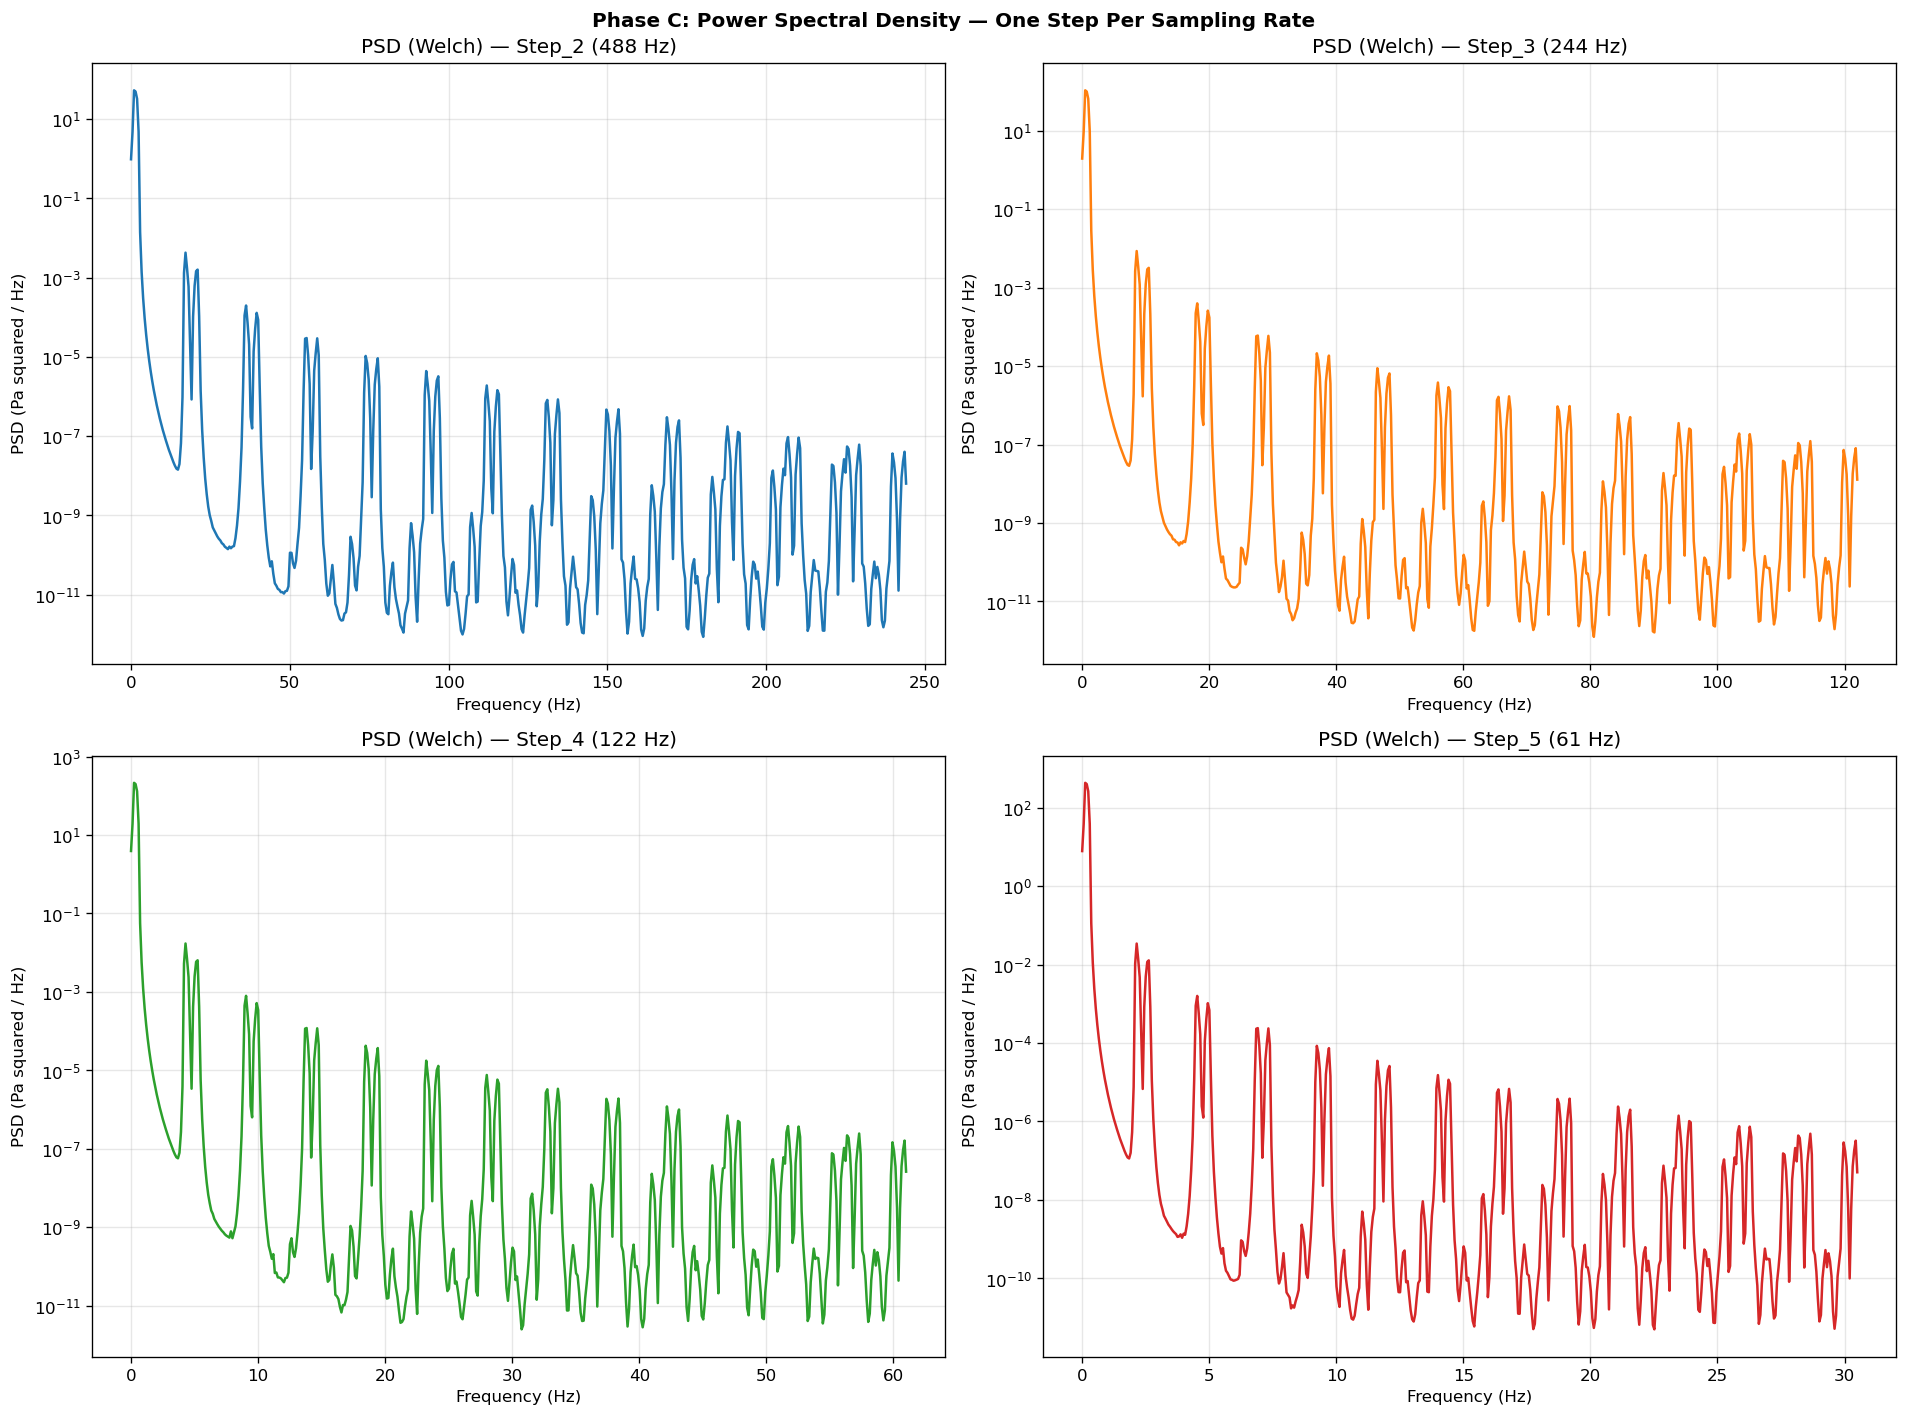

In [10]:
# ==========================================
# CELL C2: Power Spectral Density — Welch Method
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
representative_steps = {488: 'Step_2', 244: 'Step_3', 122: 'Step_4', 61: 'Step_5'}
color_by_rate = {488: '#1f77b4', 244: '#ff7f0e', 122: '#2ca02c', 61: '#d62728'}

for plot_index, (sampling_rate, sheet_name) in enumerate(representative_steps.items()):
    ax = axes.flatten()[plot_index]
    if sheet_name not in maps_steps_dictionary:
        continue
    stress_values = maps_steps_dictionary[sheet_name]['stress_Pa'].values
    freqs_welch, psd_values = welch(stress_values, fs=sampling_rate,
                                     window='hann', nperseg=min(1024, len(stress_values) // 4))
    ax.semilogy(freqs_welch, psd_values, color=color_by_rate[sampling_rate], linewidth=1.5)
    ax.set_title(f"PSD (Welch) — {sheet_name} ({sampling_rate} Hz)")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (Pa squared / Hz)")
    ax.grid(True, alpha=0.3)

plt.suptitle("Phase C: Power Spectral Density — One Step Per Sampling Rate", fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE D — Noise and Distortion Modeling

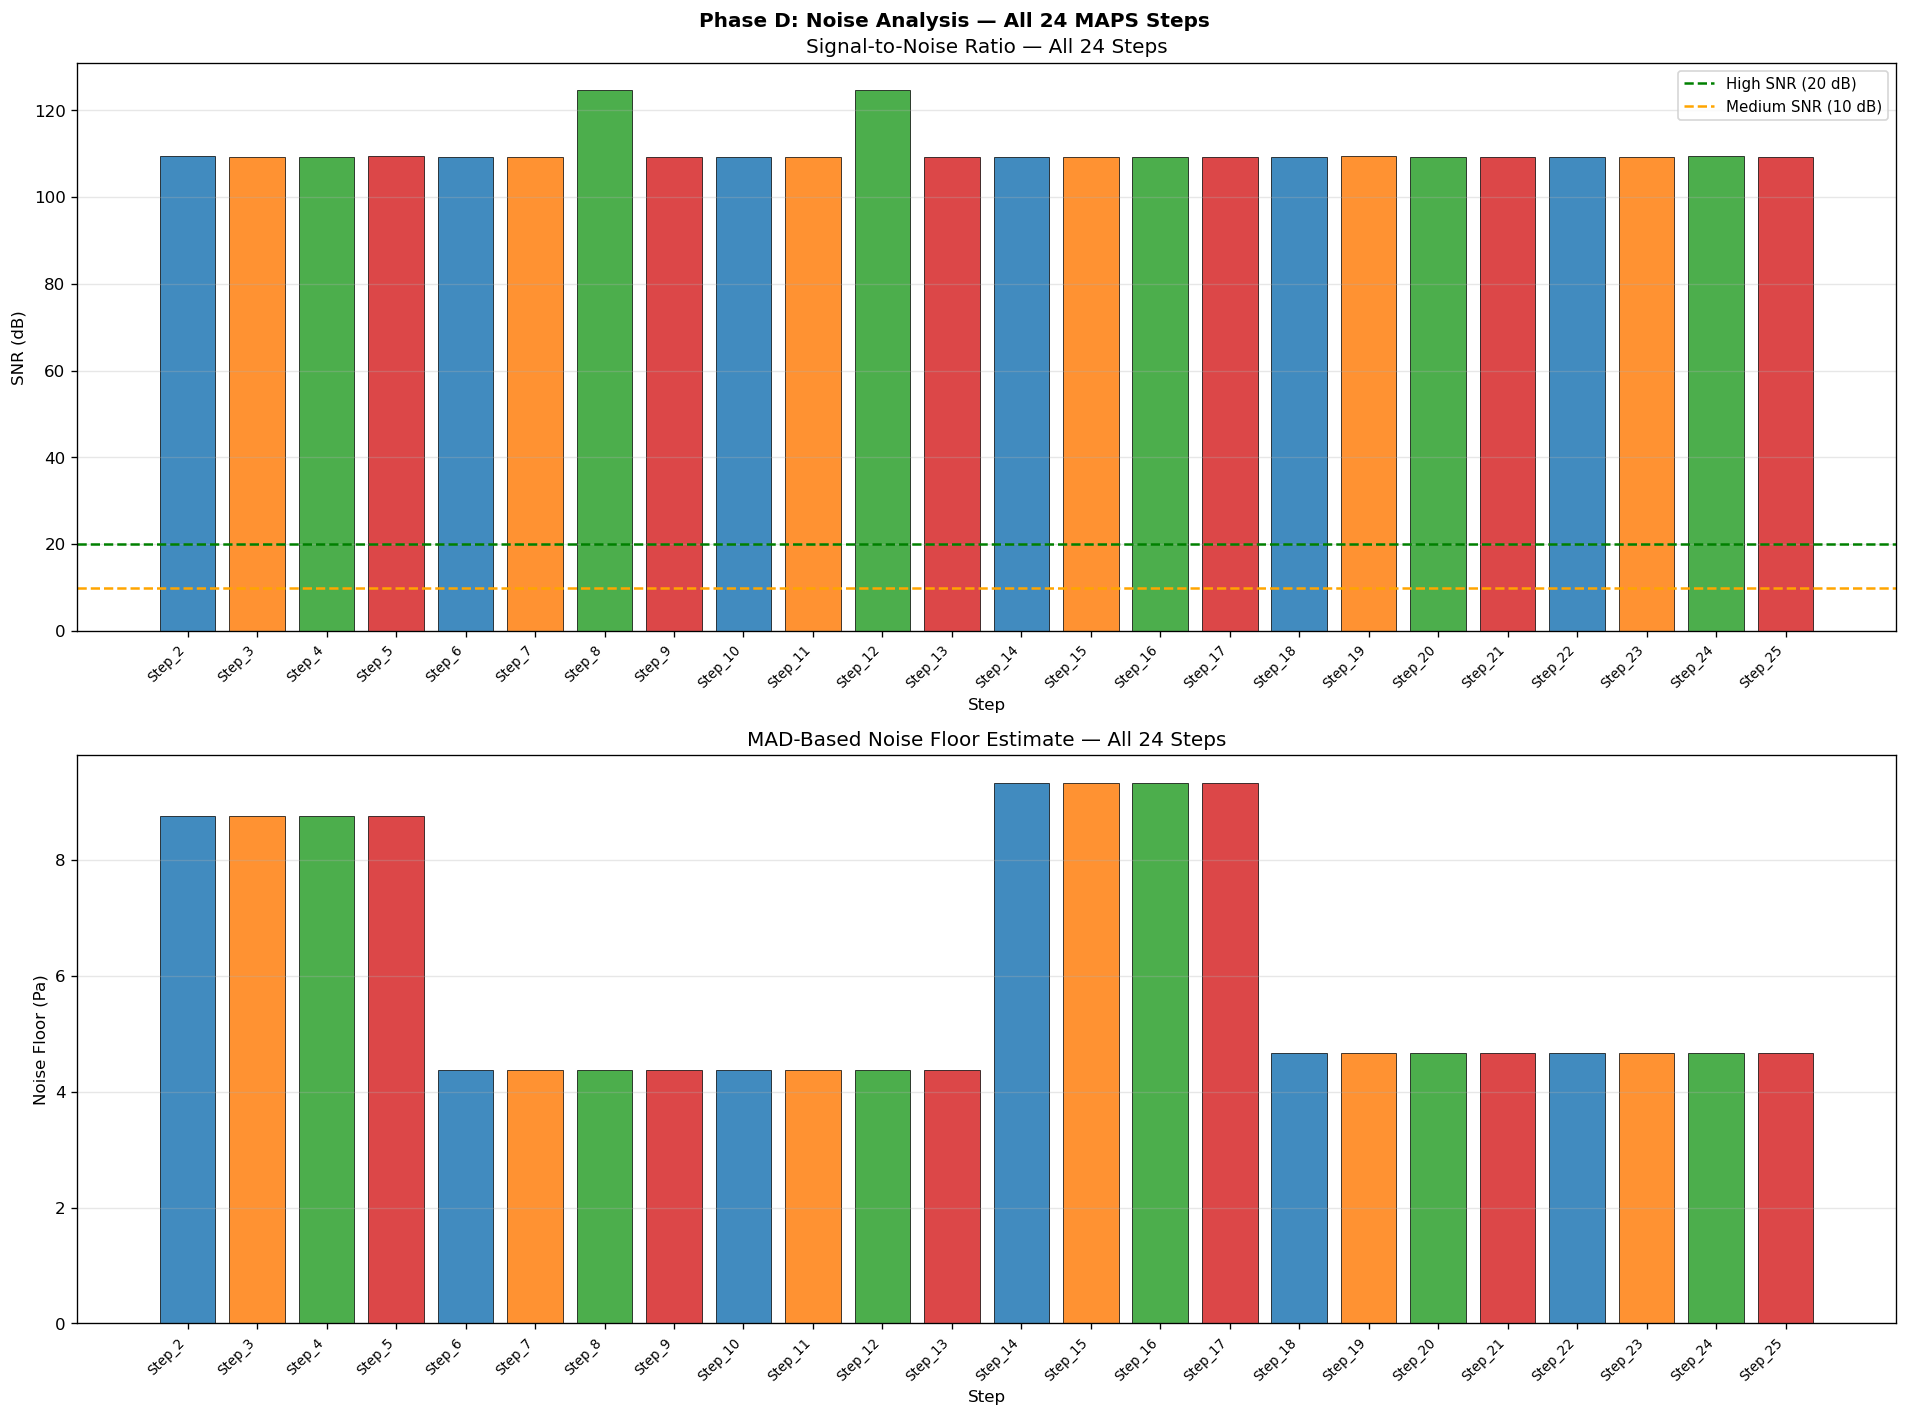

SNR Summary by Sampling Rate:
 Rate (Hz)  Mean SNR (dB)      Min      Max    Quality
-------------------------------------------------------
       488         109.34   109.26   109.56       High
       244         109.34   109.26   109.50       High
       122         114.42   109.25   124.69       High
        61         109.32   109.25   109.48       High


In [11]:
# ==========================================
# CELL D1: SNR Visualisation Across All 24 Steps
# ==========================================

fig, axes = plt.subplots(2, 1, figsize=(16, 12))

color_by_rate = {488: '#1f77b4', 244: '#ff7f0e', 122: '#2ca02c', 61: '#d62728'}
bar_colors = [color_by_rate.get(r, 'gray') for r in snr_df['Sampling_Hz']]

axes[0].bar(snr_df['Step'], snr_df['SNR_dB'], color=bar_colors, alpha=0.85, edgecolor='black', linewidth=0.5)
axes[0].axhline(y=20, color='green', linestyle='--', linewidth=1.5, label='High SNR (20 dB)')
axes[0].axhline(y=10, color='orange', linestyle='--', linewidth=1.5, label='Medium SNR (10 dB)')
axes[0].set_xlabel("Step")
axes[0].set_ylabel("SNR (dB)")
axes[0].set_title("Signal-to-Noise Ratio — All 24 Steps")
axes[0].set_xticklabels(snr_df['Step'], rotation=45, ha='right', fontsize=8)
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(snr_df['Step'], snr_df['Noise_Floor_Pa'], color=bar_colors, alpha=0.85, edgecolor='black', linewidth=0.5)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Noise Floor (Pa)")
axes[1].set_title("MAD-Based Noise Floor Estimate — All 24 Steps")
axes[1].set_xticklabels(snr_df['Step'], rotation=45, ha='right', fontsize=8)
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle("Phase D: Noise Analysis — All 24 MAPS Steps", fontweight='bold')
plt.tight_layout()
plt.show()

print("SNR Summary by Sampling Rate:")
print(f"{'Rate (Hz)':>10} {'Mean SNR (dB)':>14} {'Min':>8} {'Max':>8} {'Quality':>10}")
print("-" * 55)
for rate in [488, 244, 122, 61]:
    subset = snr_df[snr_df['Sampling_Hz'] == rate]
    if len(subset) == 0: continue
    print(f"{rate:>10} {subset['SNR_dB'].mean():>14.2f} {subset['SNR_dB'].min():>8.2f} {subset['SNR_dB'].max():>8.2f} {'High' if subset['SNR_dB'].mean() > 20 else 'Medium':>10}")

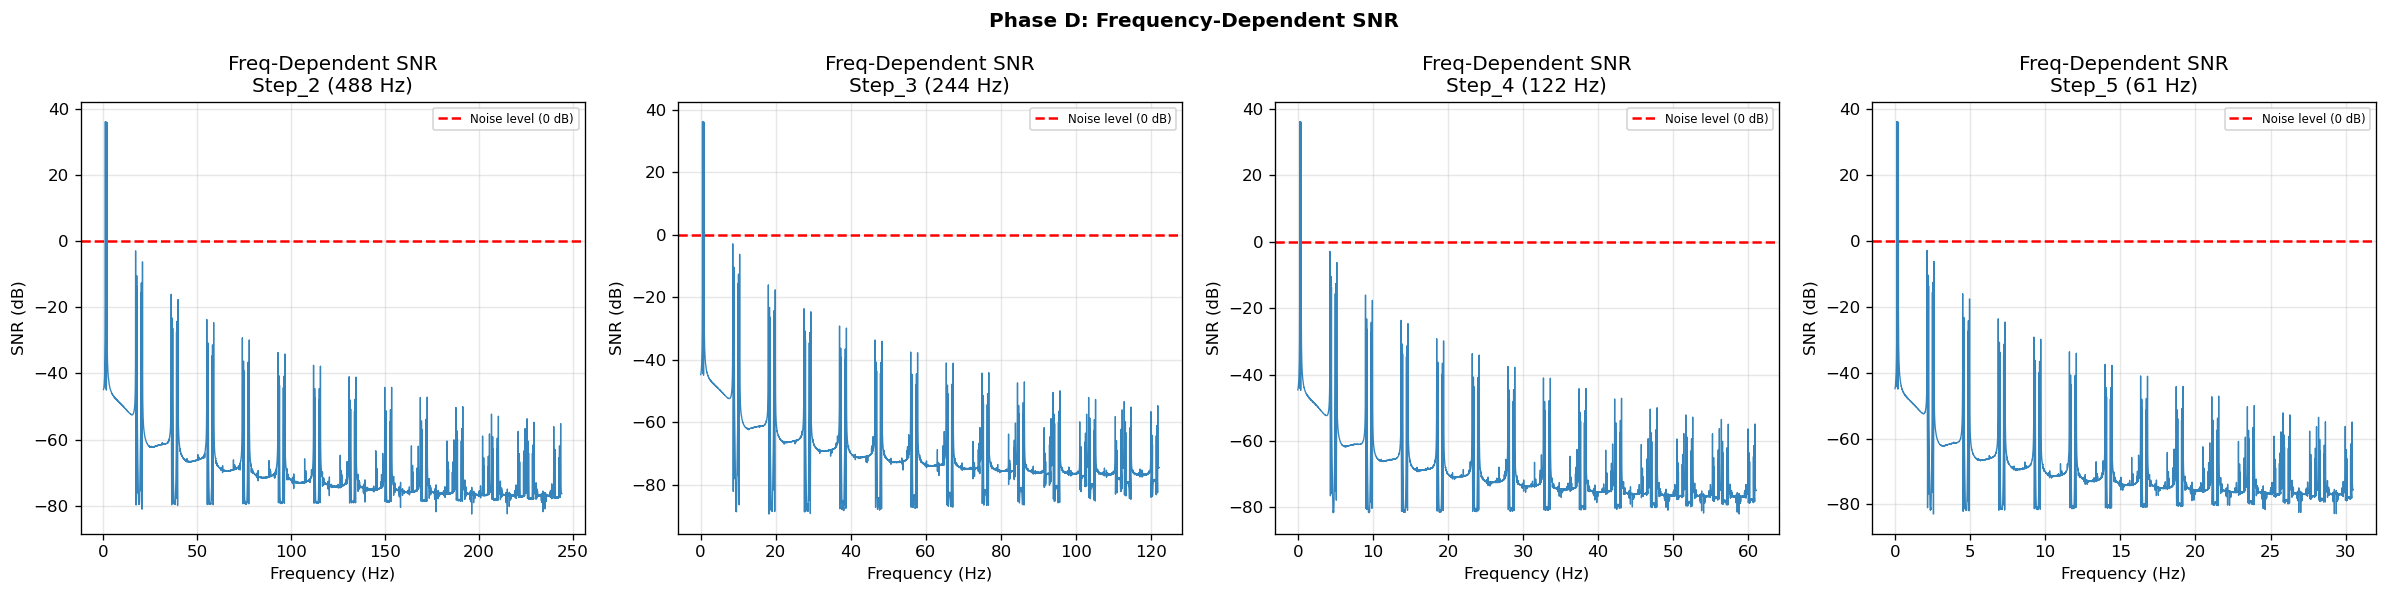

In [12]:
# ==========================================
# CELL D2: Frequency-Dependent SNR
# ==========================================

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax_index, (sampling_rate, sheet_name) in enumerate(
        {488: 'Step_2', 244: 'Step_3', 122: 'Step_4', 61: 'Step_5'}.items()):
    ax = axes[ax_index]
    if sheet_name not in maps_steps_dictionary:
        continue
    stress_values = maps_steps_dictionary[sheet_name]['stress_Pa'].values
    noise_floor   = estimate_noise_floor_mad(stress_values)
    fft_complex   = np.fft.fft(stress_values)
    fft_magnitude = np.abs(fft_complex)
    freq_bins     = np.fft.fftfreq(len(stress_values), d=1.0 / sampling_rate)
    positive_mask = freq_bins > 0
    positive_freqs = freq_bins[positive_mask]
    positive_mags  = fft_magnitude[positive_mask]
    freq_snr_db    = 20.0 * np.log10(positive_mags / (noise_floor * np.sqrt(len(stress_values)) + 1e-12))
    ax.plot(positive_freqs, freq_snr_db, linewidth=0.8, alpha=0.9)
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Noise level (0 dB)')
    ax.set_title(f"Freq-Dependent SNR\n{sheet_name} ({sampling_rate} Hz)")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("SNR (dB)")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle("Phase D: Frequency-Dependent SNR", fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE E — Spectral Leakage and Window Analysis

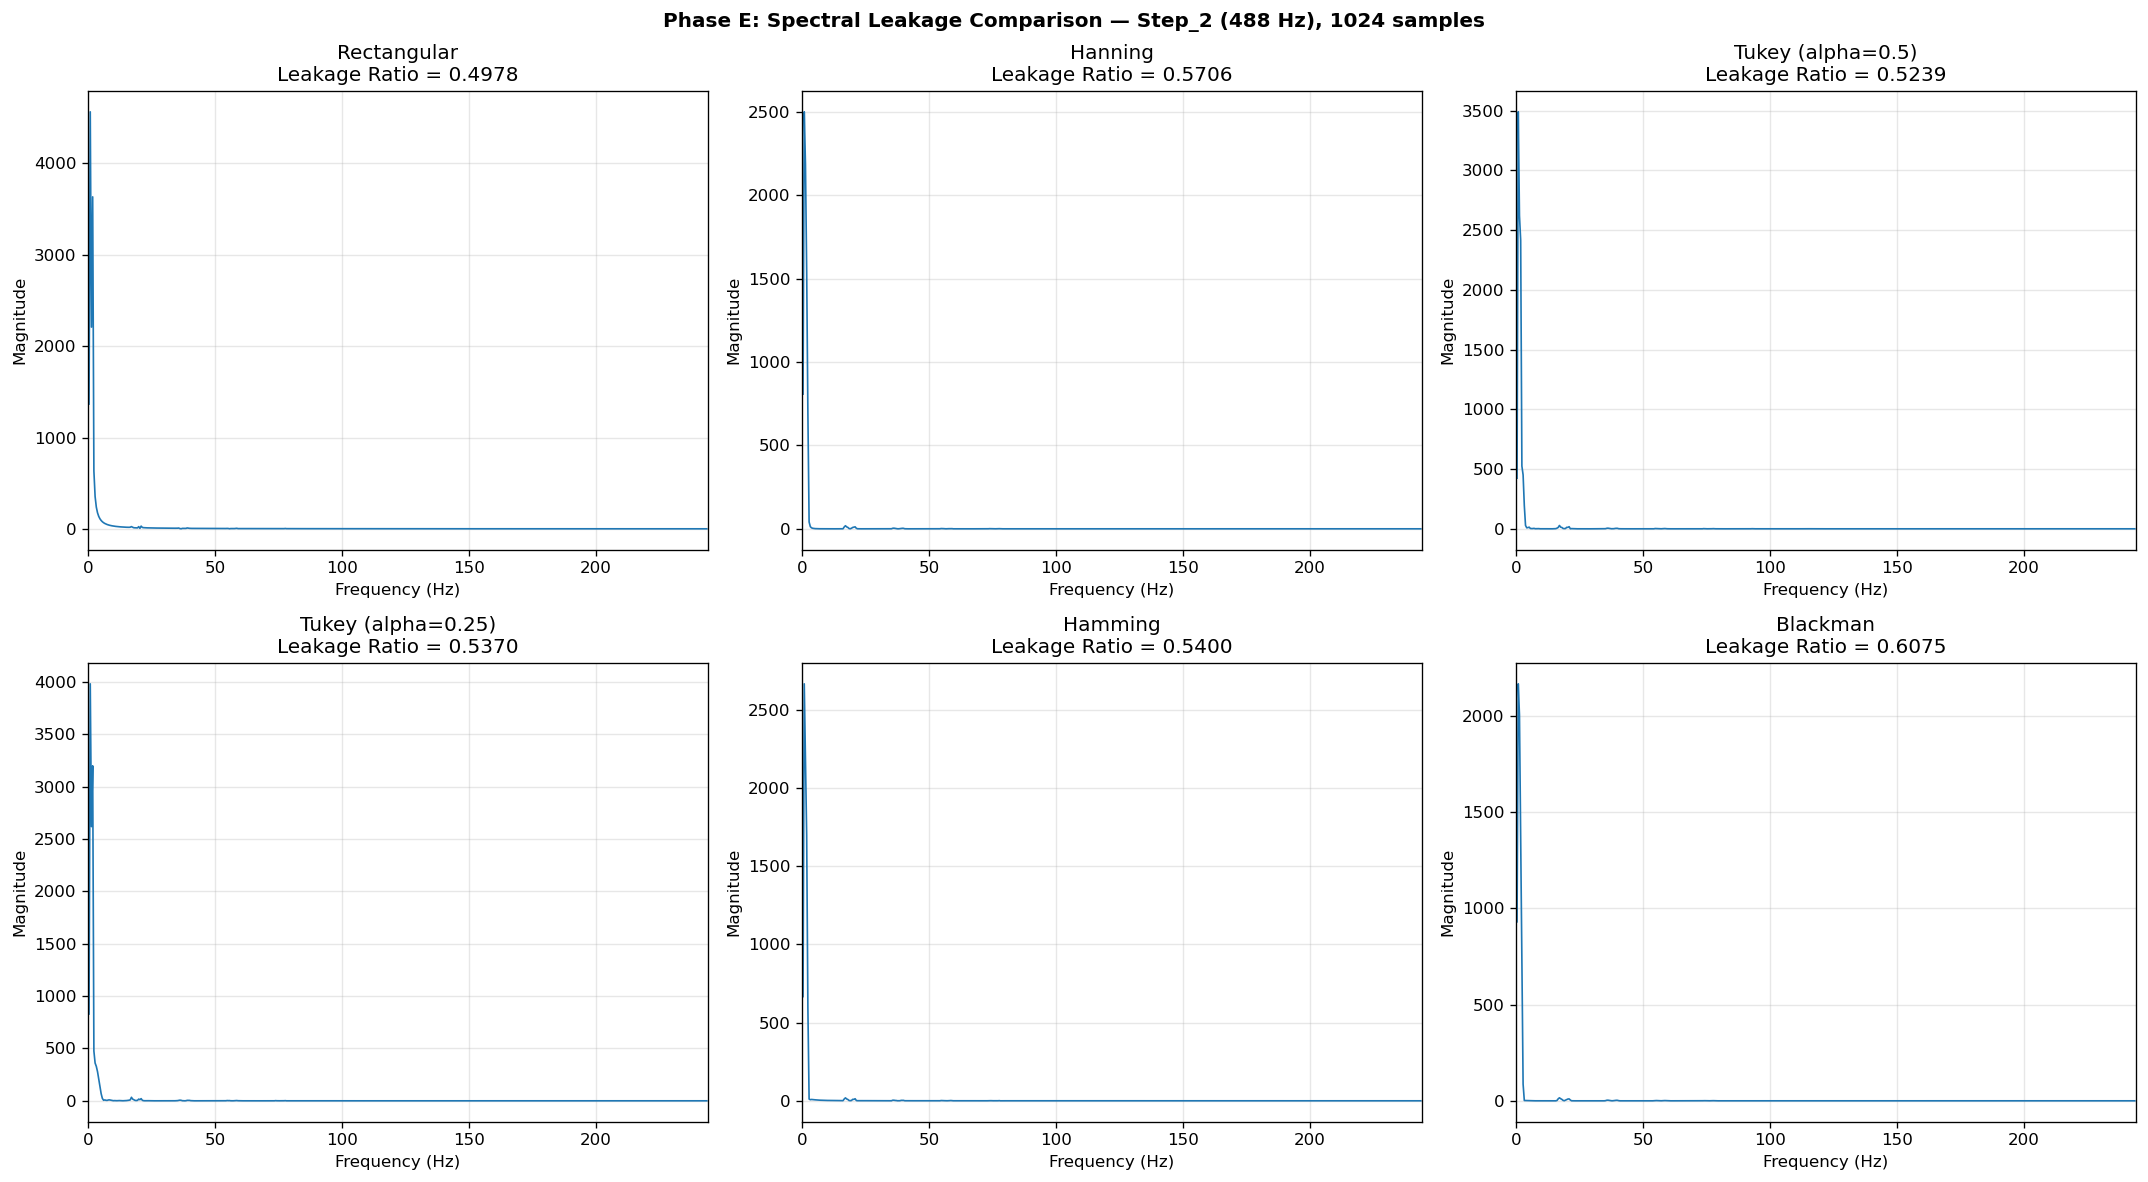


Leakage Comparison Table:
            Window  Leakage Ratio
       Rectangular       0.497816
           Hanning       0.570590
 Tukey (alpha=0.5)       0.523896
Tukey (alpha=0.25)       0.536953
           Hamming       0.540037
          Blackman       0.607537


In [13]:
# ==========================================
# CELL E1: Window Function Comparison — 1024-Point Segment
# ==========================================

reference_step   = 'Step_2'
sampling_rate_ref = 488
n_samples_window = 1024
signal_segment   = maps_steps_dictionary[reference_step]['stress_Pa'].values[:n_samples_window]

window_definitions = {
    'Rectangular':        np.ones(n_samples_window),
    'Hanning':            scipy_windows.hann(n_samples_window),
    'Tukey (alpha=0.5)':  scipy_windows.tukey(n_samples_window, alpha=0.5),
    'Tukey (alpha=0.25)': scipy_windows.tukey(n_samples_window, alpha=0.25),
    'Hamming':            scipy_windows.hamming(n_samples_window),
    'Blackman':           scipy_windows.blackman(n_samples_window)
}

freq_axis      = np.fft.fftfreq(n_samples_window, d=1.0 / sampling_rate_ref)
positive_mask  = freq_axis > 0
positive_freqs = freq_axis[positive_mask]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat  = axes.flatten()
leakage_records = []

for plot_index, (window_name, window_values) in enumerate(window_definitions.items()):
    windowed_signal = signal_segment * window_values
    fft_complex     = np.fft.fft(windowed_signal)
    fft_magnitude   = np.abs(fft_complex)[positive_mask]
    peak_energy     = np.max(fft_magnitude) ** 2
    total_energy    = np.sum(fft_magnitude ** 2)
    leakage_ratio   = 1.0 - (peak_energy / (total_energy + 1e-12))
    leakage_records.append({'Window': window_name, 'Leakage Ratio': leakage_ratio})
    ax = axes_flat[plot_index]
    ax.plot(positive_freqs, fft_magnitude, linewidth=1.0)
    ax.set_title(f"{window_name}\nLeakage Ratio = {leakage_ratio:.4f}")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Magnitude")
    ax.set_xlim(0, sampling_rate_ref / 2)
    ax.grid(True, alpha=0.3)

plt.suptitle(f"Phase E: Spectral Leakage Comparison — {reference_step} ({sampling_rate_ref} Hz), {n_samples_window} samples",
             fontweight='bold')
plt.tight_layout()
plt.show()

leakage_df = pd.DataFrame(leakage_records)
print("\nLeakage Comparison Table:")
print(leakage_df.to_string(index=False))

In [14]:
# ==========================================
# CELL E2: Heisenberg Uncertainty — Window Length vs Resolution
# ==========================================

window_lengths_to_test = [64, 128, 256, 512, 1024, 2048]
print("=" * 65)
print("HEISENBERG UNCERTAINTY — STFT WINDOW LENGTH vs RESOLUTION")
print("=" * 65)
print(f"{'Window Length':>14} {'Time Res (s)':>14} {'Freq Res (Hz)':>14} {'Product':>10}")
print("-" * 55)

heisenberg_records = []
for window_length in window_lengths_to_test:
    time_resolution_s   = window_length / 488.0
    freq_resolution_hz  = 1.0 / time_resolution_s
    uncertainty_product = time_resolution_s * freq_resolution_hz
    heisenberg_records.append({'Window Length': window_length,
                                'Time Res (s)': time_resolution_s,
                                'Freq Res (Hz)': freq_resolution_hz,
                                'Product': uncertainty_product})
    print(f"{window_length:>14} {time_resolution_s:>14.4f} {freq_resolution_hz:>14.4f} {uncertainty_product:>10.4f}")

heisenberg_df = pd.DataFrame(heisenberg_records)
print("\nProduct is always 1.0 — Heisenberg uncertainty principle for STFT.")
print("CWT breaks this by using scale-dependent window length.")

HEISENBERG UNCERTAINTY — STFT WINDOW LENGTH vs RESOLUTION
 Window Length   Time Res (s)  Freq Res (Hz)    Product
-------------------------------------------------------
            64         0.1311         7.6250     1.0000
           128         0.2623         3.8125     1.0000
           256         0.5246         1.9062     1.0000
           512         1.0492         0.9531     1.0000
          1024         2.0984         0.4766     1.0000
          2048         4.1967         0.2383     1.0000

Product is always 1.0 — Heisenberg uncertainty principle for STFT.
CWT breaks this by using scale-dependent window length.


## PHASE F — Fourier Ecosystem Analysis

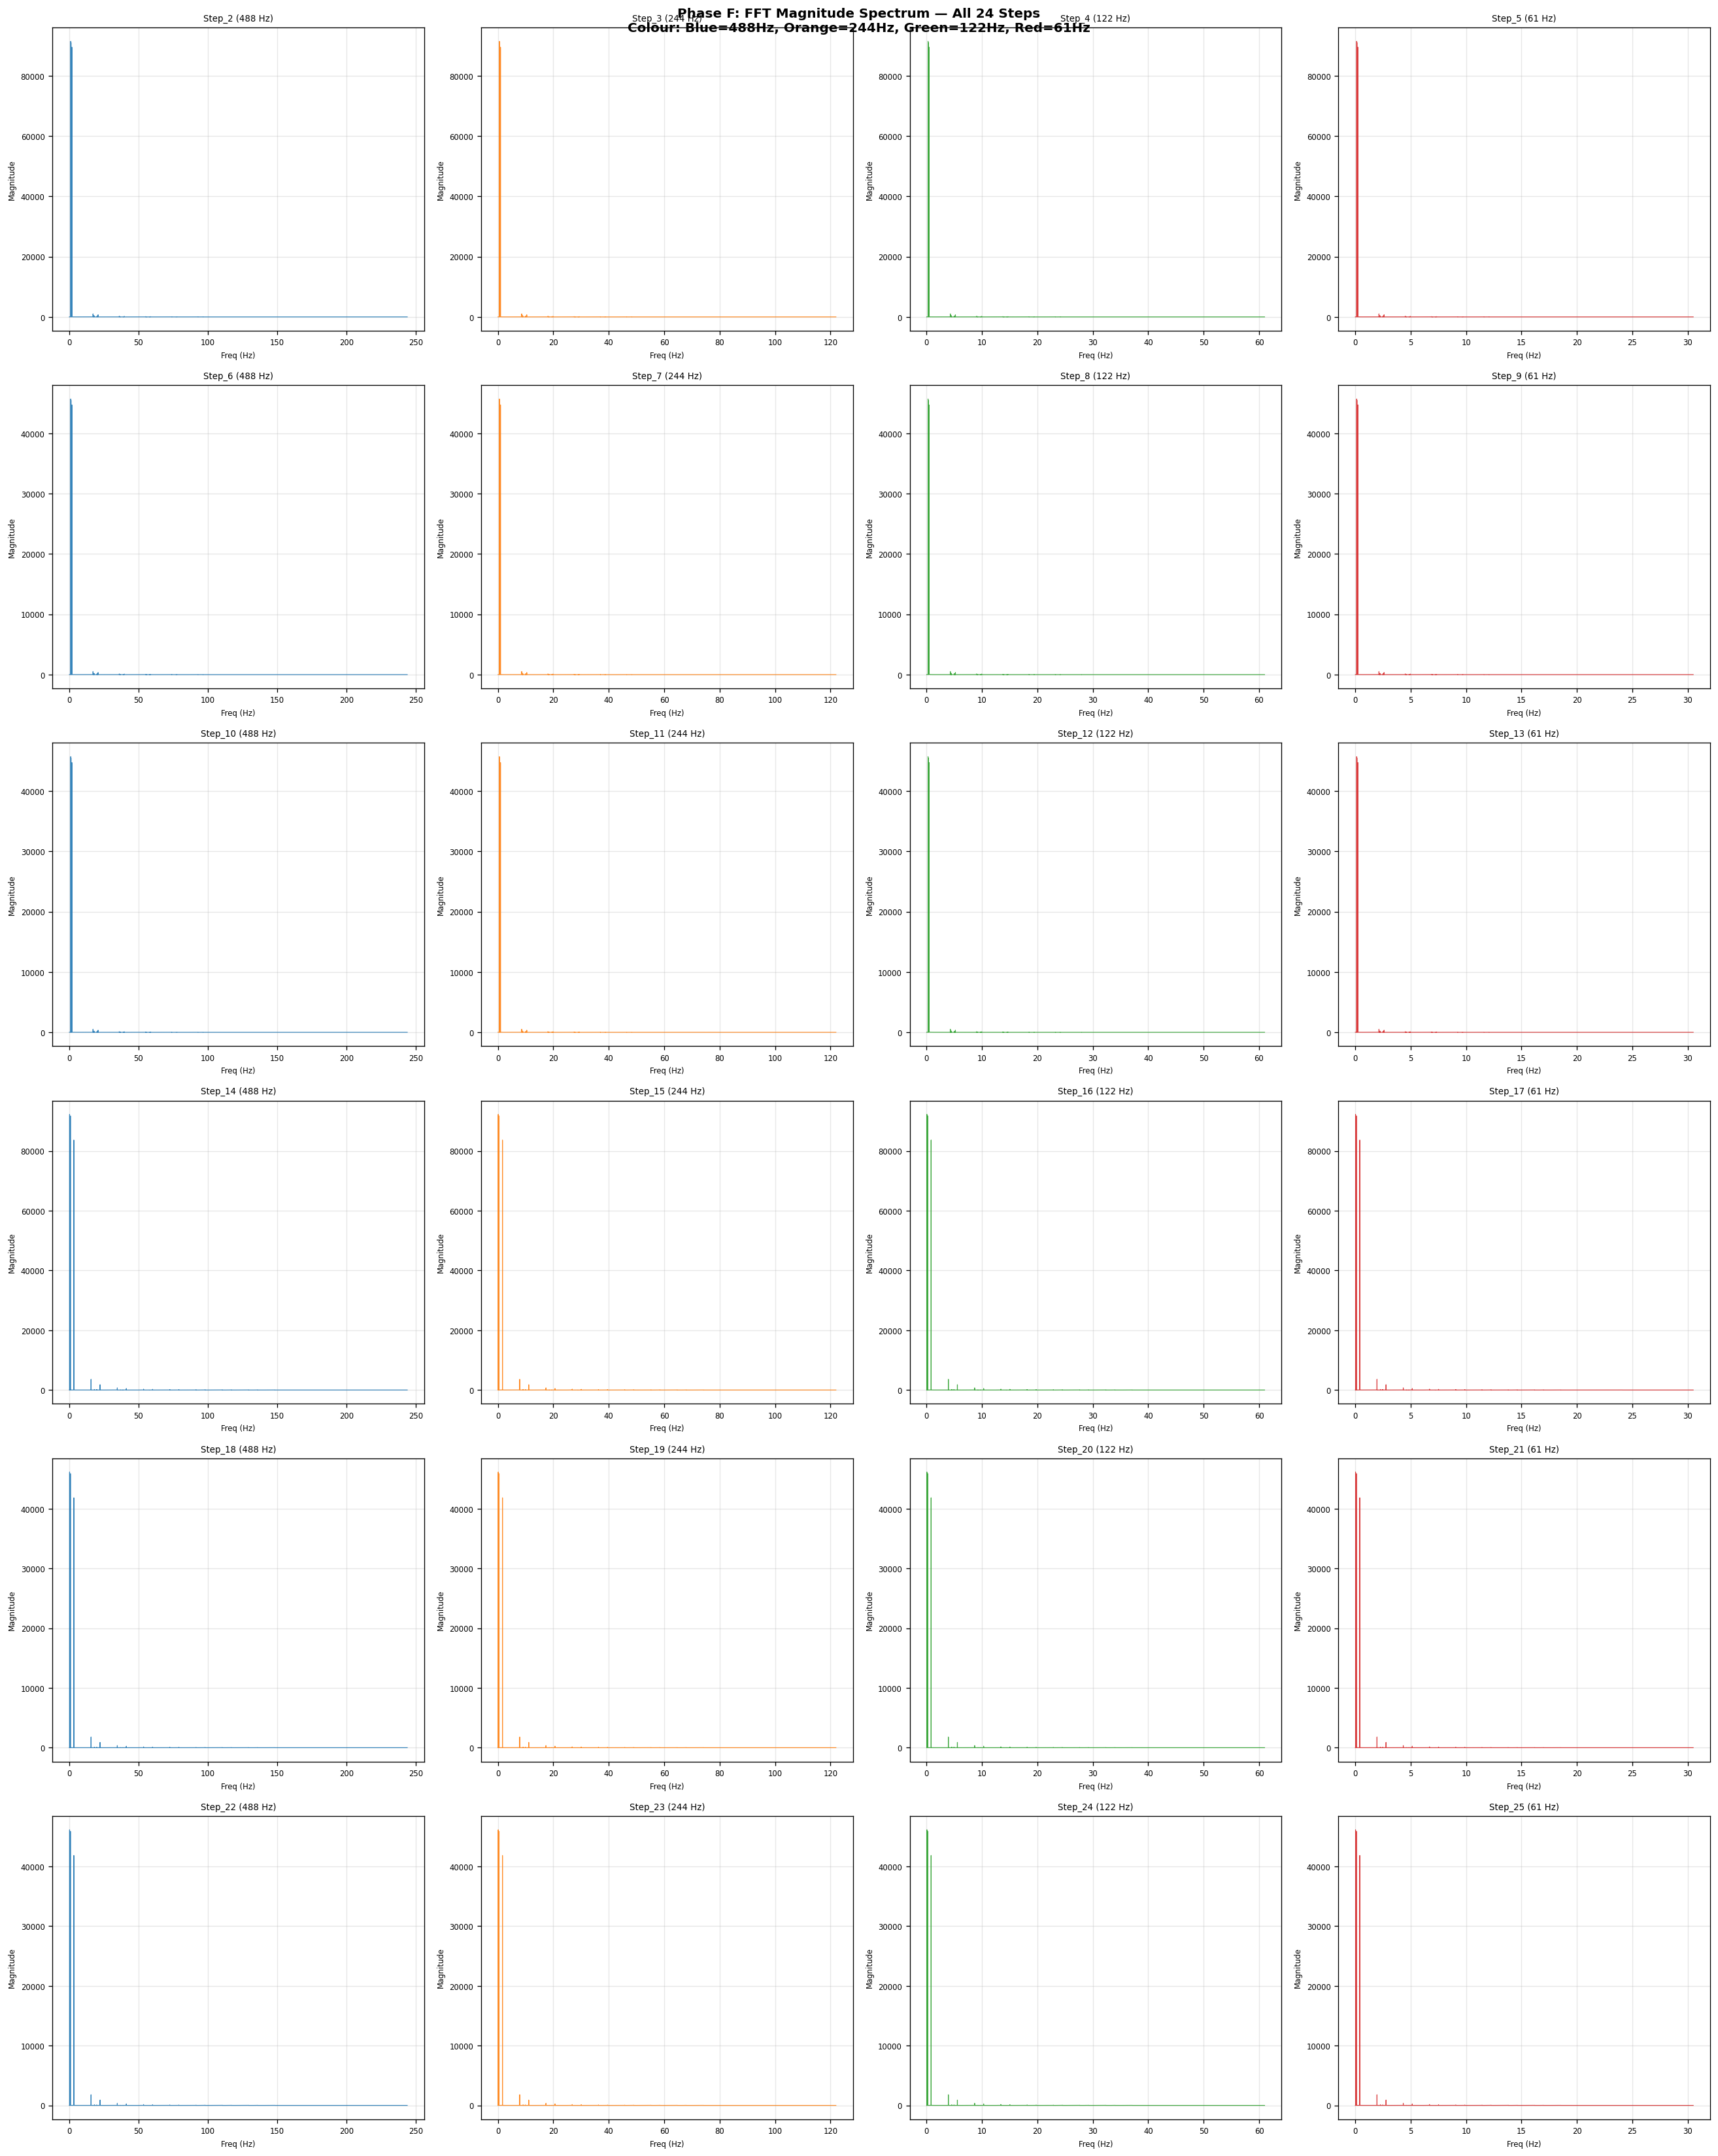

In [16]:
# ==========================================
# CELL F1: FFT on All 24 Steps — Stress Signal
# ==========================================

fig, axes = plt.subplots(6, 4, figsize=(22, 28))
axes_flat = axes.flatten()
fft_results_dictionary = {}

for step_number in range(2, 26):
    sheet_name    = f"Step_{step_number}"
    ax = axes_flat[step_number - 2]
    if sheet_name not in maps_steps_dictionary:
        ax.set_visible(False)
        continue
    df            = maps_steps_dictionary[sheet_name]
    stress_values = df['stress_Pa'].values
    sampling_rate = step_metadata_df[step_metadata_df['Sheet'] == sheet_name]['Sampling_Hz'].values[0]
    fft_complex   = np.fft.fft(stress_values)
    fft_magnitude = np.abs(fft_complex)
    freq_bins     = np.fft.fftfreq(len(stress_values), d=1.0 / sampling_rate)
    positive_mask = freq_bins > 0
    positive_freqs = freq_bins[positive_mask]
    positive_mags  = fft_magnitude[positive_mask]
    fft_results_dictionary[sheet_name] = {
        'frequencies': positive_freqs, 'magnitudes': positive_mags, 'sampling_rate': sampling_rate
    }
    ax.plot(positive_freqs, positive_mags, linewidth=0.7, alpha=0.9,
            color={488: '#1f77b4', 244: '#ff7f0e', 122: '#2ca02c', 61: '#d62728'}.get(sampling_rate, 'gray'))
    ax.set_title(f"{sheet_name} ({sampling_rate} Hz)", fontsize=8)
    ax.set_xlabel("Freq (Hz)", fontsize=7)
    ax.set_ylabel("Magnitude", fontsize=7)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=7)

plt.suptitle("Phase F: FFT Magnitude Spectrum — All 24 Steps\nColour: Blue=488Hz, Orange=244Hz, Green=122Hz, Red=61Hz",
             fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# CELL F2: Dominant Frequency Extraction — All 24 Steps
# ==========================================

print("=" * 75)
print("DOMINANT FREQUENCY EXTRACTION — ALL 24 STEPS")
print("=" * 75)
print(f"{'Step':>8} {'Hz':>6} {'Dominant Freq (Hz)':>20} {'Peak Magnitude':>15} {'Energy Fraction':>16}")
print("-" * 72)

dominant_freq_records = []

for step_number in range(2, 26):
    sheet_name = f"Step_{step_number}"
    if sheet_name not in fft_results_dictionary:
        continue
    fft_data           = fft_results_dictionary[sheet_name]
    positive_freqs     = fft_data['frequencies']
    positive_mags      = fft_data['magnitudes']
    sampling_rate      = fft_data['sampling_rate']
    peak_index         = np.argmax(positive_mags)
    dominant_frequency = positive_freqs[peak_index]
    peak_magnitude     = positive_mags[peak_index]
    total_energy       = np.sum(positive_mags ** 2)
    peak_energy_frac   = (peak_magnitude ** 2) / (total_energy + 1e-12)
    dominant_freq_records.append({
        'Step': sheet_name, 'Sampling_Hz': sampling_rate,
        'Dominant_Freq_Hz': dominant_frequency, 'Peak_Magnitude': peak_magnitude,
        'Energy_Fraction': peak_energy_frac
    })
    print(f"{sheet_name:>8} {sampling_rate:>6} {dominant_frequency:>20.4f} {peak_magnitude:>15.4f} {peak_energy_frac:>16.4f}")

dominant_freq_df = pd.DataFrame(dominant_freq_records)

DOMINANT FREQUENCY EXTRACTION — ALL 24 STEPS
    Step     Hz   Dominant Freq (Hz)  Peak Magnitude  Energy Fraction
------------------------------------------------------------------------
  Step_2    488               1.0180      91422.7037           0.3391
  Step_3    244               0.5090      91422.7033           0.3391
  Step_4    122               0.2545      91422.7000           0.3391
  Step_5     61               0.1272      91422.7095           0.3391
  Step_6    488               1.0180      45711.3507           0.3391
  Step_7    244               0.5090      45711.3513           0.3391
  Step_8    122               0.2545      45723.5910           0.3393
  Step_9     61               0.1272      45711.3529           0.3391
 Step_10    488               1.0180      45711.3500           0.3391
 Step_11    244               0.5090      45711.3509           0.3391
 Step_12    122               0.2545      45723.5905           0.3393
 Step_13     61               0.1272      

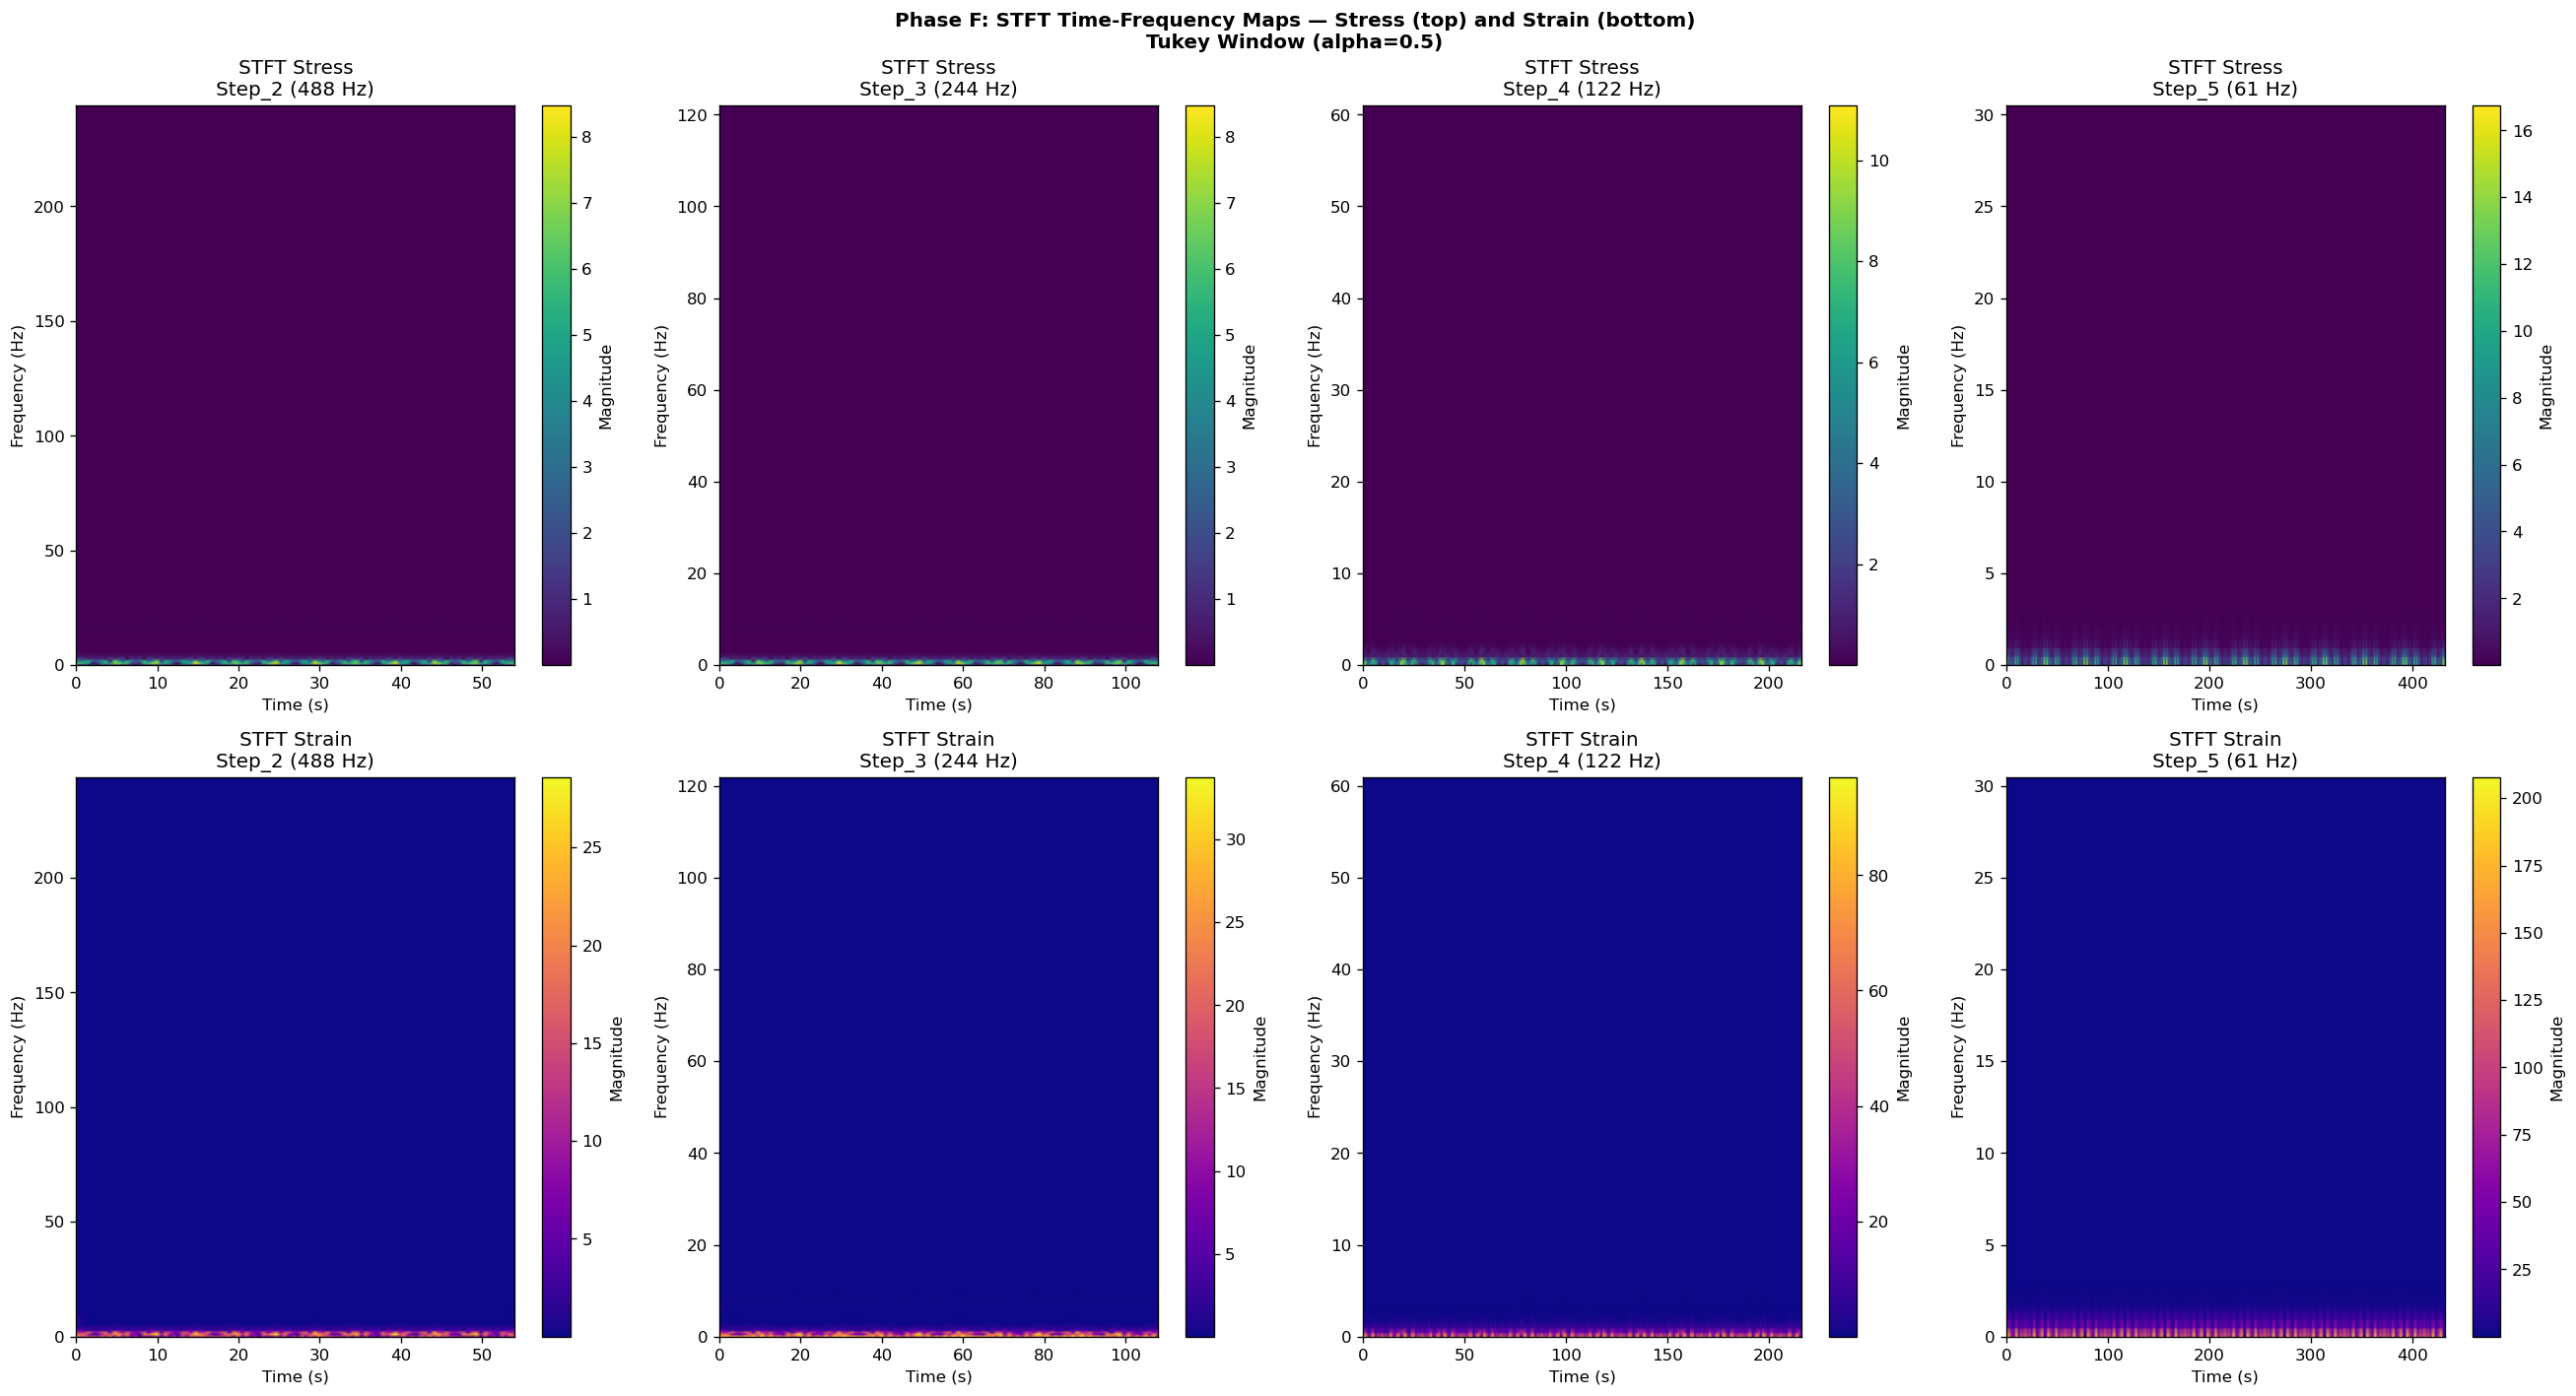

In [18]:
# ==========================================
# CELL F3: STFT Time-Frequency Maps — Four Sampling Rates
# ==========================================

fig, axes = plt.subplots(2, 4, figsize=(22, 12))
steps_to_plot     = {488: 'Step_2', 244: 'Step_3', 122: 'Step_4', 61: 'Step_5'}
window_lengths_stft = {488: 512, 244: 512, 122: 256, 61: 128}

for col_index, (sampling_rate, sheet_name) in enumerate(steps_to_plot.items()):
    if sheet_name not in maps_steps_dictionary:
        continue
    df            = maps_steps_dictionary[sheet_name]
    stress_values = df['stress_Pa'].values
    strain_values = df['strain_pct'].values
    window_length = window_lengths_stft[sampling_rate]
    tukey_window  = scipy_windows.tukey(window_length, alpha=0.5)

    stft_freqs_s, stft_times_s, stft_complex_s = stft(
        stress_values, fs=sampling_rate, window=tukey_window,
        nperseg=window_length, noverlap=window_length // 2
    )
    img1 = axes[0, col_index].pcolormesh(stft_times_s, stft_freqs_s,
        np.abs(stft_complex_s), shading='gouraud', cmap='viridis')
    plt.colorbar(img1, ax=axes[0, col_index], label="Magnitude")
    axes[0, col_index].set_title(f"STFT Stress\n{sheet_name} ({sampling_rate} Hz)")
    axes[0, col_index].set_xlabel("Time (s)")
    axes[0, col_index].set_ylabel("Frequency (Hz)")

    stft_freqs_t, stft_times_t, stft_complex_t = stft(
        strain_values, fs=sampling_rate, window=tukey_window,
        nperseg=window_length, noverlap=window_length // 2
    )
    img2 = axes[1, col_index].pcolormesh(stft_times_t, stft_freqs_t,
        np.abs(stft_complex_t), shading='gouraud', cmap='plasma')
    plt.colorbar(img2, ax=axes[1, col_index], label="Magnitude")
    axes[1, col_index].set_title(f"STFT Strain\n{sheet_name} ({sampling_rate} Hz)")
    axes[1, col_index].set_xlabel("Time (s)")
    axes[1, col_index].set_ylabel("Frequency (Hz)")

plt.suptitle("Phase F: STFT Time-Frequency Maps — Stress (top) and Strain (bottom)\nTukey Window (alpha=0.5)",
             fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE G — Continuous Wavelet Transform

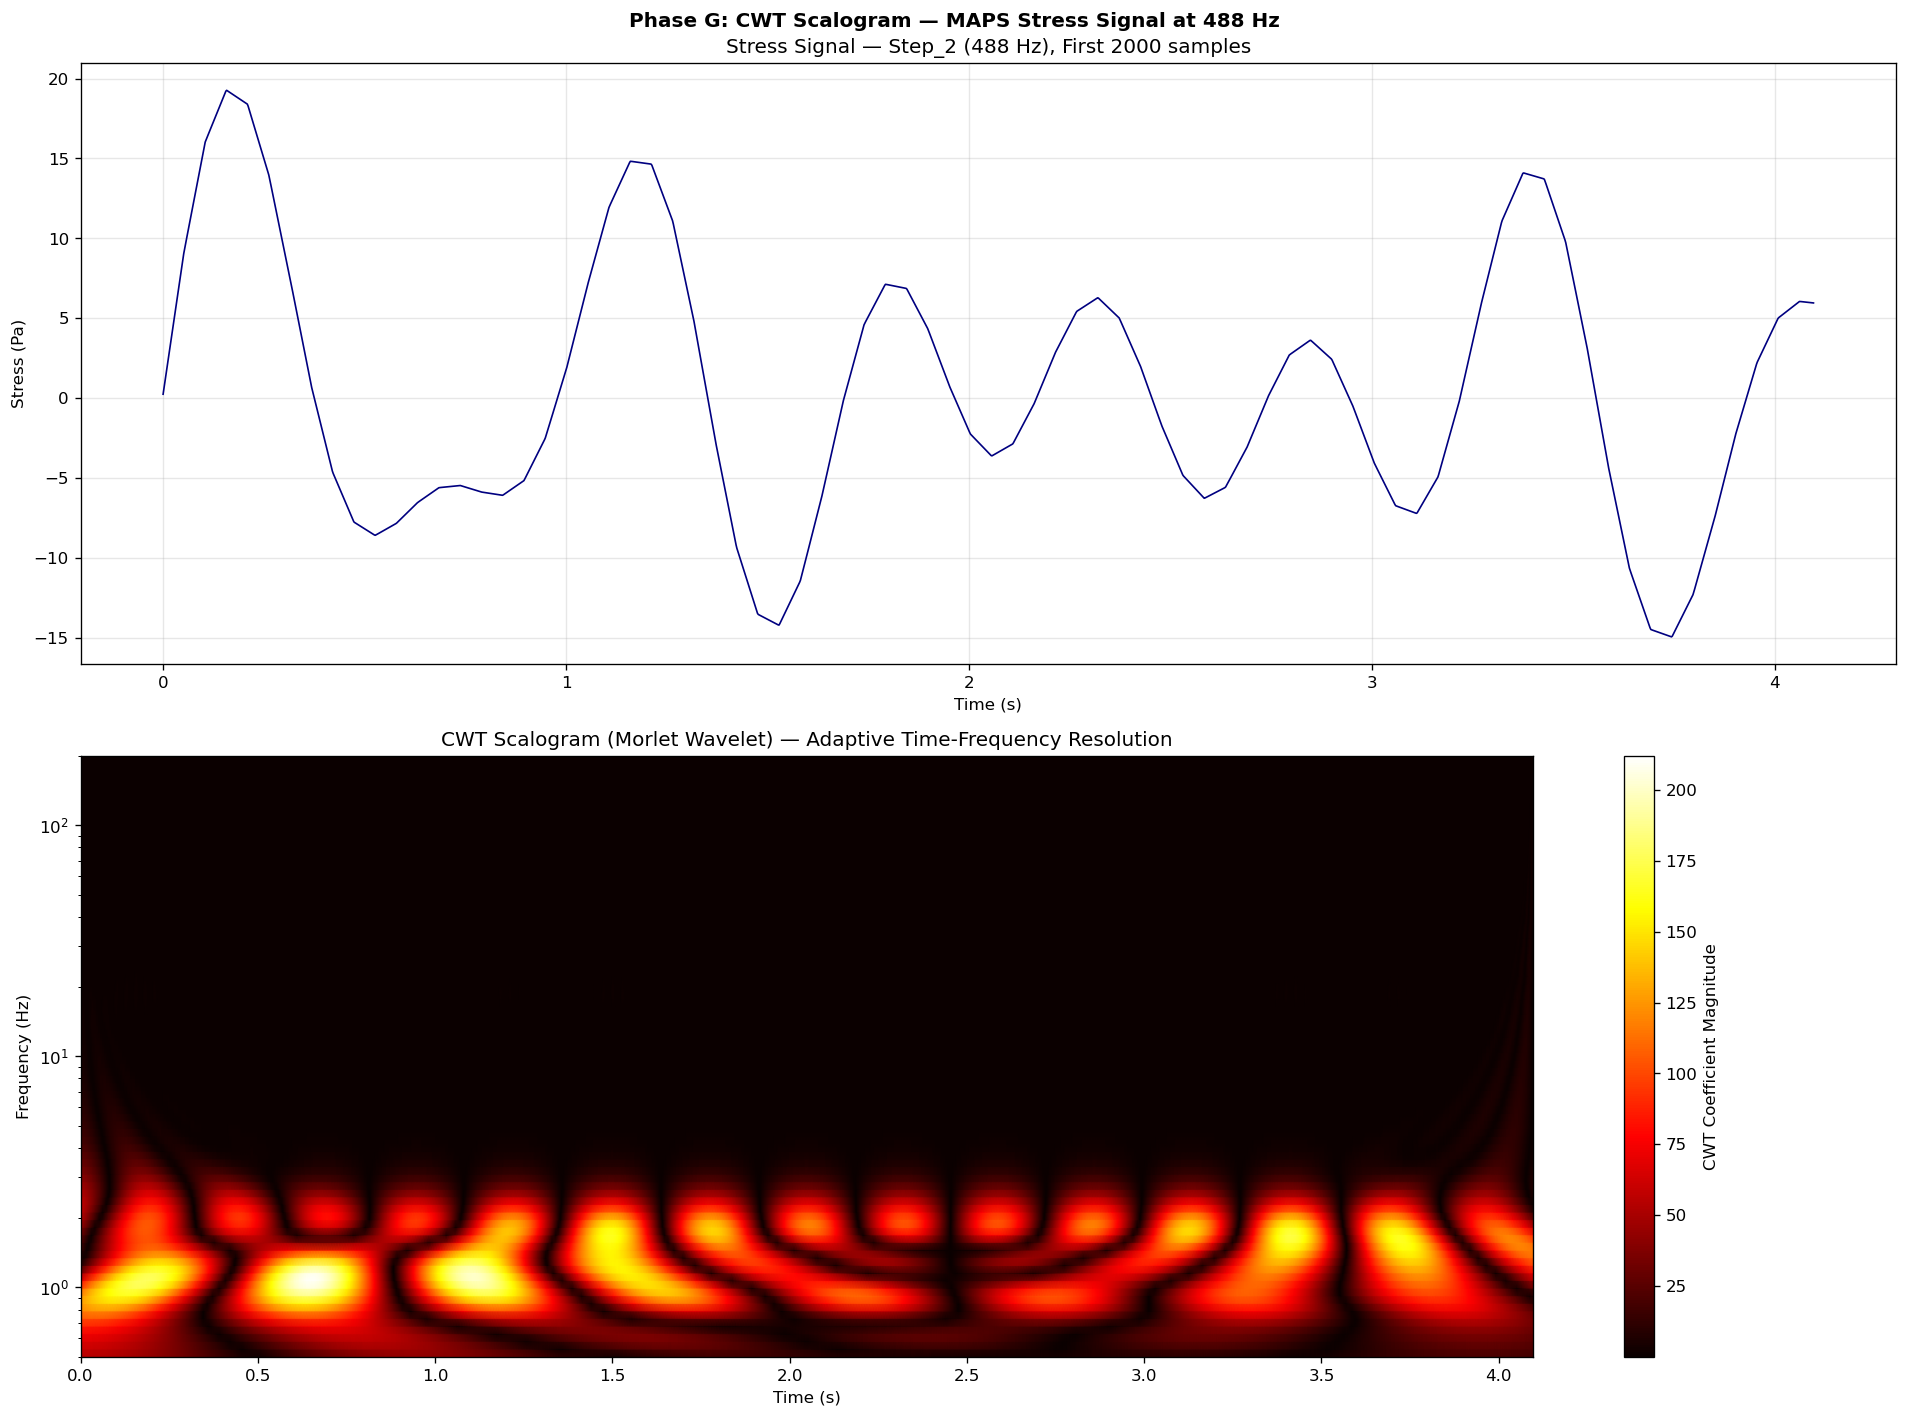

Frequency range resolved: 0.50 to 200.00 Hz
CWT provides adaptive resolution — advantage over STFT on broadband signals.


In [19]:
# ==========================================
# CELL G1: CWT on Reference Step — Step_1 (488 Hz)
# ==========================================

import pywt

reference_step      = 'Step_2'
sampling_rate_cwt   = 488
n_points_cwt        = 2000
stress_for_cwt      = maps_steps_dictionary[reference_step]['stress_Pa'].values[:n_points_cwt]
time_axis_cwt       = np.arange(n_points_cwt) / sampling_rate_cwt
morlet_central_freq = pywt.central_frequency('morl')
target_frequencies  = np.logspace(np.log10(0.5), np.log10(200), 80)
scales_array        = morlet_central_freq * sampling_rate_cwt / target_frequencies

cwt_coefficients, cwt_frequencies = pywt.cwt(
    stress_for_cwt, scales_array, 'morl', sampling_period=1.0 / sampling_rate_cwt
)

fig, axes = plt.subplots(2, 1, figsize=(16, 12))

axes[0].plot(time_axis_cwt, stress_for_cwt, linewidth=1.0, color='navy')
axes[0].set_title(f"Stress Signal — {reference_step} ({sampling_rate_cwt} Hz), First {n_points_cwt} samples")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Stress (Pa)")
axes[0].grid(True, alpha=0.3)

img = axes[1].pcolormesh(
    time_axis_cwt, cwt_frequencies, np.abs(cwt_coefficients), shading='gouraud', cmap='hot'
)
plt.colorbar(img, ax=axes[1], label="CWT Coefficient Magnitude")
axes[1].set_title("CWT Scalogram (Morlet Wavelet) — Adaptive Time-Frequency Resolution")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_yscale('log')

plt.suptitle("Phase G: CWT Scalogram — MAPS Stress Signal at 488 Hz", fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Frequency range resolved: {cwt_frequencies.min():.2f} to {cwt_frequencies.max():.2f} Hz")
print("CWT provides adaptive resolution — advantage over STFT on broadband signals.")

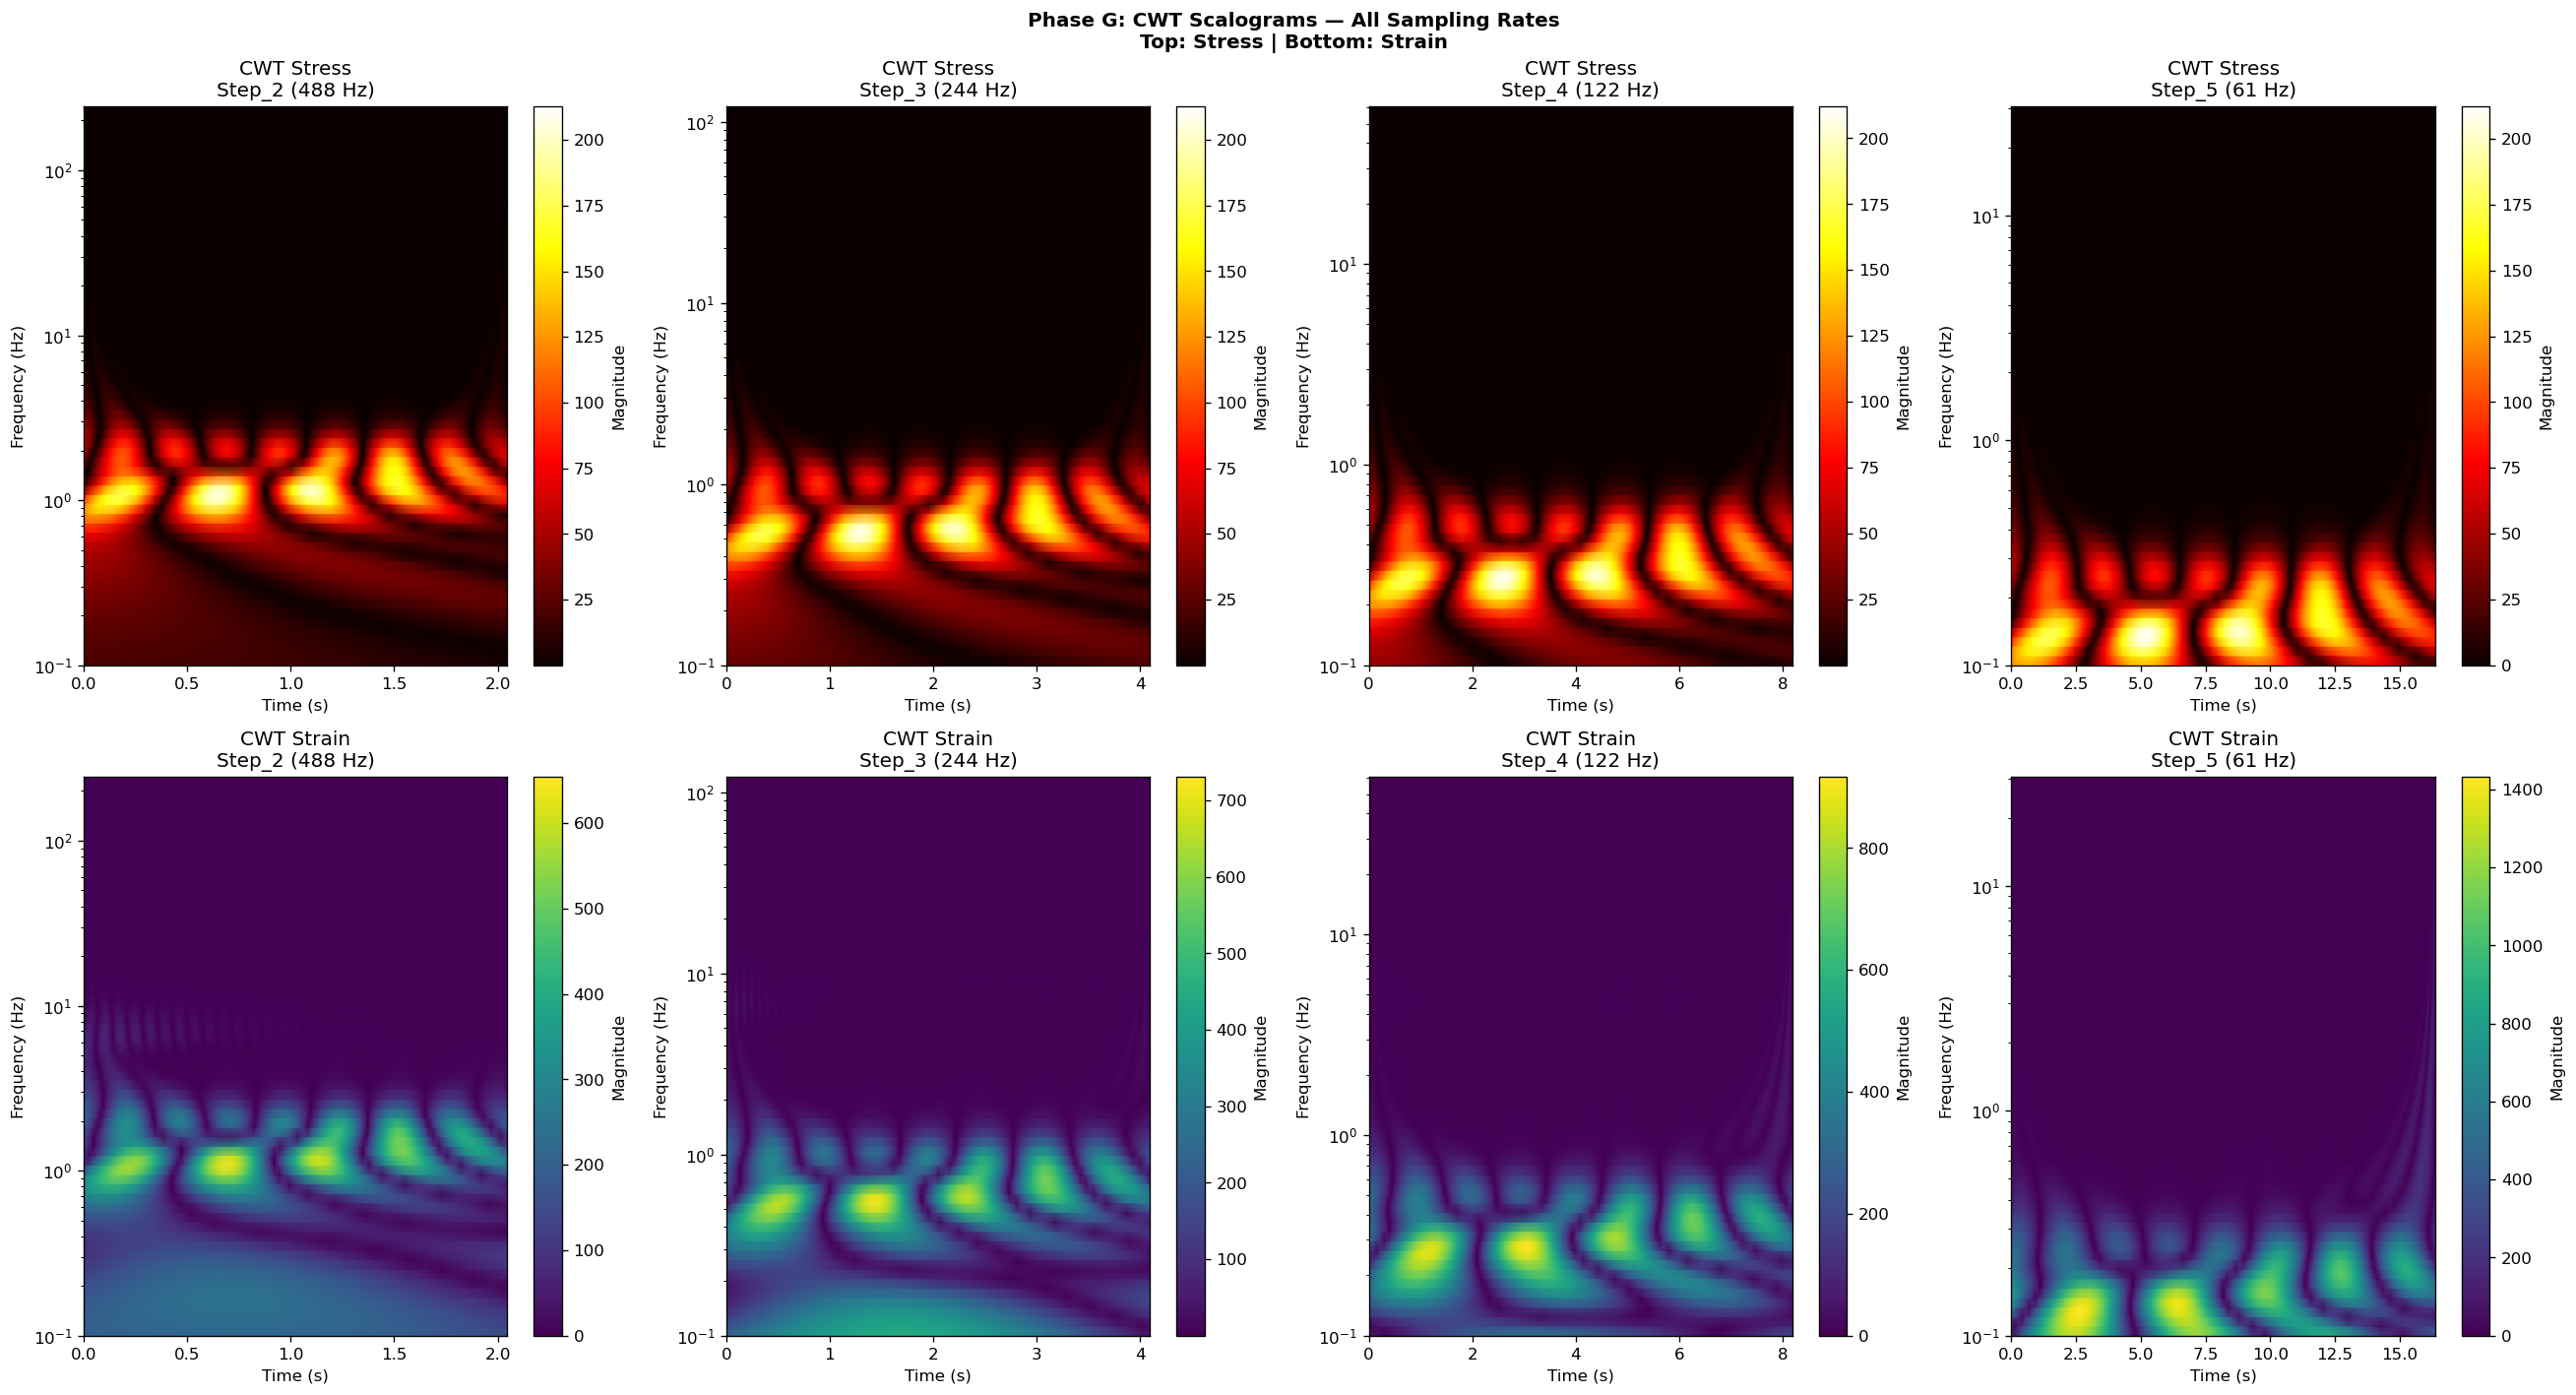

In [20]:
# ==========================================
# CELL G2: CWT Across All Four Sampling Rates
# ==========================================

import pywt

steps_to_plot_cwt = {488: 'Step_2', 244: 'Step_3', 122: 'Step_4', 61: 'Step_5'}
n_points_plot     = 1000
morlet_central_freq = pywt.central_frequency('morl')

fig, axes = plt.subplots(2, 4, figsize=(22, 12))

for col_index, (sampling_rate, sheet_name) in enumerate(steps_to_plot_cwt.items()):
    if sheet_name not in maps_steps_dictionary:
        continue
    stress_segment = maps_steps_dictionary[sheet_name]['stress_Pa'].values[:n_points_plot]
    strain_segment = maps_steps_dictionary[sheet_name]['strain_pct'].values[:n_points_plot]
    time_segment   = np.arange(n_points_plot) / sampling_rate

    target_freqs = np.logspace(np.log10(0.1), np.log10(sampling_rate / 2.0), 60)
    scales_cwt   = morlet_central_freq * sampling_rate / target_freqs

    cwt_stress, cwt_freqs = pywt.cwt(stress_segment, scales_cwt, 'morl',
                                       sampling_period=1.0 / sampling_rate)
    cwt_strain, _         = pywt.cwt(strain_segment, scales_cwt, 'morl',
                                       sampling_period=1.0 / sampling_rate)

    img1 = axes[0, col_index].pcolormesh(time_segment, cwt_freqs,
        np.abs(cwt_stress), shading='gouraud', cmap='hot')
    plt.colorbar(img1, ax=axes[0, col_index], label="Magnitude")
    axes[0, col_index].set_title(f"CWT Stress\n{sheet_name} ({sampling_rate} Hz)")
    axes[0, col_index].set_xlabel("Time (s)")
    axes[0, col_index].set_ylabel("Frequency (Hz)")
    axes[0, col_index].set_yscale('log')

    img2 = axes[1, col_index].pcolormesh(time_segment, cwt_freqs,
        np.abs(cwt_strain), shading='gouraud', cmap='viridis')
    plt.colorbar(img2, ax=axes[1, col_index], label="Magnitude")
    axes[1, col_index].set_title(f"CWT Strain\n{sheet_name} ({sampling_rate} Hz)")
    axes[1, col_index].set_xlabel("Time (s)")
    axes[1, col_index].set_ylabel("Frequency (Hz)")
    axes[1, col_index].set_yscale('log')

plt.suptitle("Phase G: CWT Scalograms — All Sampling Rates\nTop: Stress | Bottom: Strain",
             fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE I — Harmonic Content and Nonlinear Analysis

In [21]:
# ==========================================
# CELL I1: Harmonic Detection — All 24 Steps
# ==========================================

print("=" * 85)
print("HARMONIC DETECTION — 3rd, 5th, 7th HARMONICS AND TOTAL HARMONIC DISTORTION")
print("=" * 85)
print(f"{'Step':>8} {'Hz':>6} {'Fund (Hz)':>11} {'3rd (Hz)':>10} {'5th (Hz)':>10} {'7th (Hz)':>10} {'THD (%)':>10}")
print("-" * 72)

harmonic_records = []

def find_harmonic_magnitude(frequencies, magnitudes, target_freq, tolerance_fraction=0.1):
    tolerance = max(target_freq * tolerance_fraction, 0.5)
    mask = np.abs(frequencies - target_freq) < tolerance
    return np.max(magnitudes[mask]) if np.any(mask) else 0.0

for step_number in range(2, 26):
    sheet_name = f"Step_{step_number}"
    if sheet_name not in fft_results_dictionary:
        continue
    fft_data           = fft_results_dictionary[sheet_name]
    positive_freqs     = fft_data['frequencies']
    positive_mags      = fft_data['magnitudes']
    sampling_rate      = fft_data['sampling_rate']
    peak_index         = np.argmax(positive_mags)
    fundamental_freq   = positive_freqs[peak_index]
    fundamental_mag    = positive_mags[peak_index]
    mag_3rd  = find_harmonic_magnitude(positive_freqs, positive_mags, 3.0 * fundamental_freq)
    mag_5th  = find_harmonic_magnitude(positive_freqs, positive_mags, 5.0 * fundamental_freq)
    mag_7th  = find_harmonic_magnitude(positive_freqs, positive_mags, 7.0 * fundamental_freq)
    thd_value = (np.sqrt(mag_3rd**2 + mag_5th**2 + mag_7th**2) / (fundamental_mag + 1e-12)) * 100.0
    harmonic_records.append({
        'Step': sheet_name, 'Sampling_Hz': sampling_rate,
        'Fundamental_Hz': fundamental_freq,
        'Mag_3rd': mag_3rd, 'Mag_5th': mag_5th, 'Mag_7th': mag_7th, 'THD_pct': thd_value
    })
    print(f"{sheet_name:>8} {sampling_rate:>6} {fundamental_freq:>11.3f} {3*fundamental_freq:>10.3f} {5*fundamental_freq:>10.3f} {7*fundamental_freq:>10.3f} {thd_value:>10.3f}")

harmonic_df = pd.DataFrame(harmonic_records)
print(f"\nMean THD across all steps: {harmonic_df['THD_pct'].mean():.3f}%")
print(f"THD < 5%: {'Yes — predominantly linear response' if harmonic_df['THD_pct'].mean() < 5 else 'No — significant nonlinearity detected'}")

HARMONIC DETECTION — 3rd, 5th, 7th HARMONICS AND TOTAL HARMONIC DISTORTION
    Step     Hz   Fund (Hz)   3rd (Hz)   5th (Hz)   7th (Hz)    THD (%)
------------------------------------------------------------------------
  Step_2    488       1.018      3.054      5.090      7.126      0.017
  Step_3    244       0.509      1.527      2.545      3.563      0.033
  Step_4    122       0.254      0.763      1.272      1.781     99.555
  Step_5     61       0.127      0.382      0.636      0.891    141.107
  Step_6    488       1.018      3.054      5.090      7.126      0.018
  Step_7    244       0.509      1.527      2.545      3.563      0.033
  Step_8    122       0.254      0.763      1.272      1.781     99.516
  Step_9     61       0.127      0.382      0.636      0.891    141.107
 Step_10    488       1.018      3.054      5.090      7.126      0.018
 Step_11    244       0.509      1.527      2.545      3.563      0.033
 Step_12    122       0.254      0.763      1.272      1.781

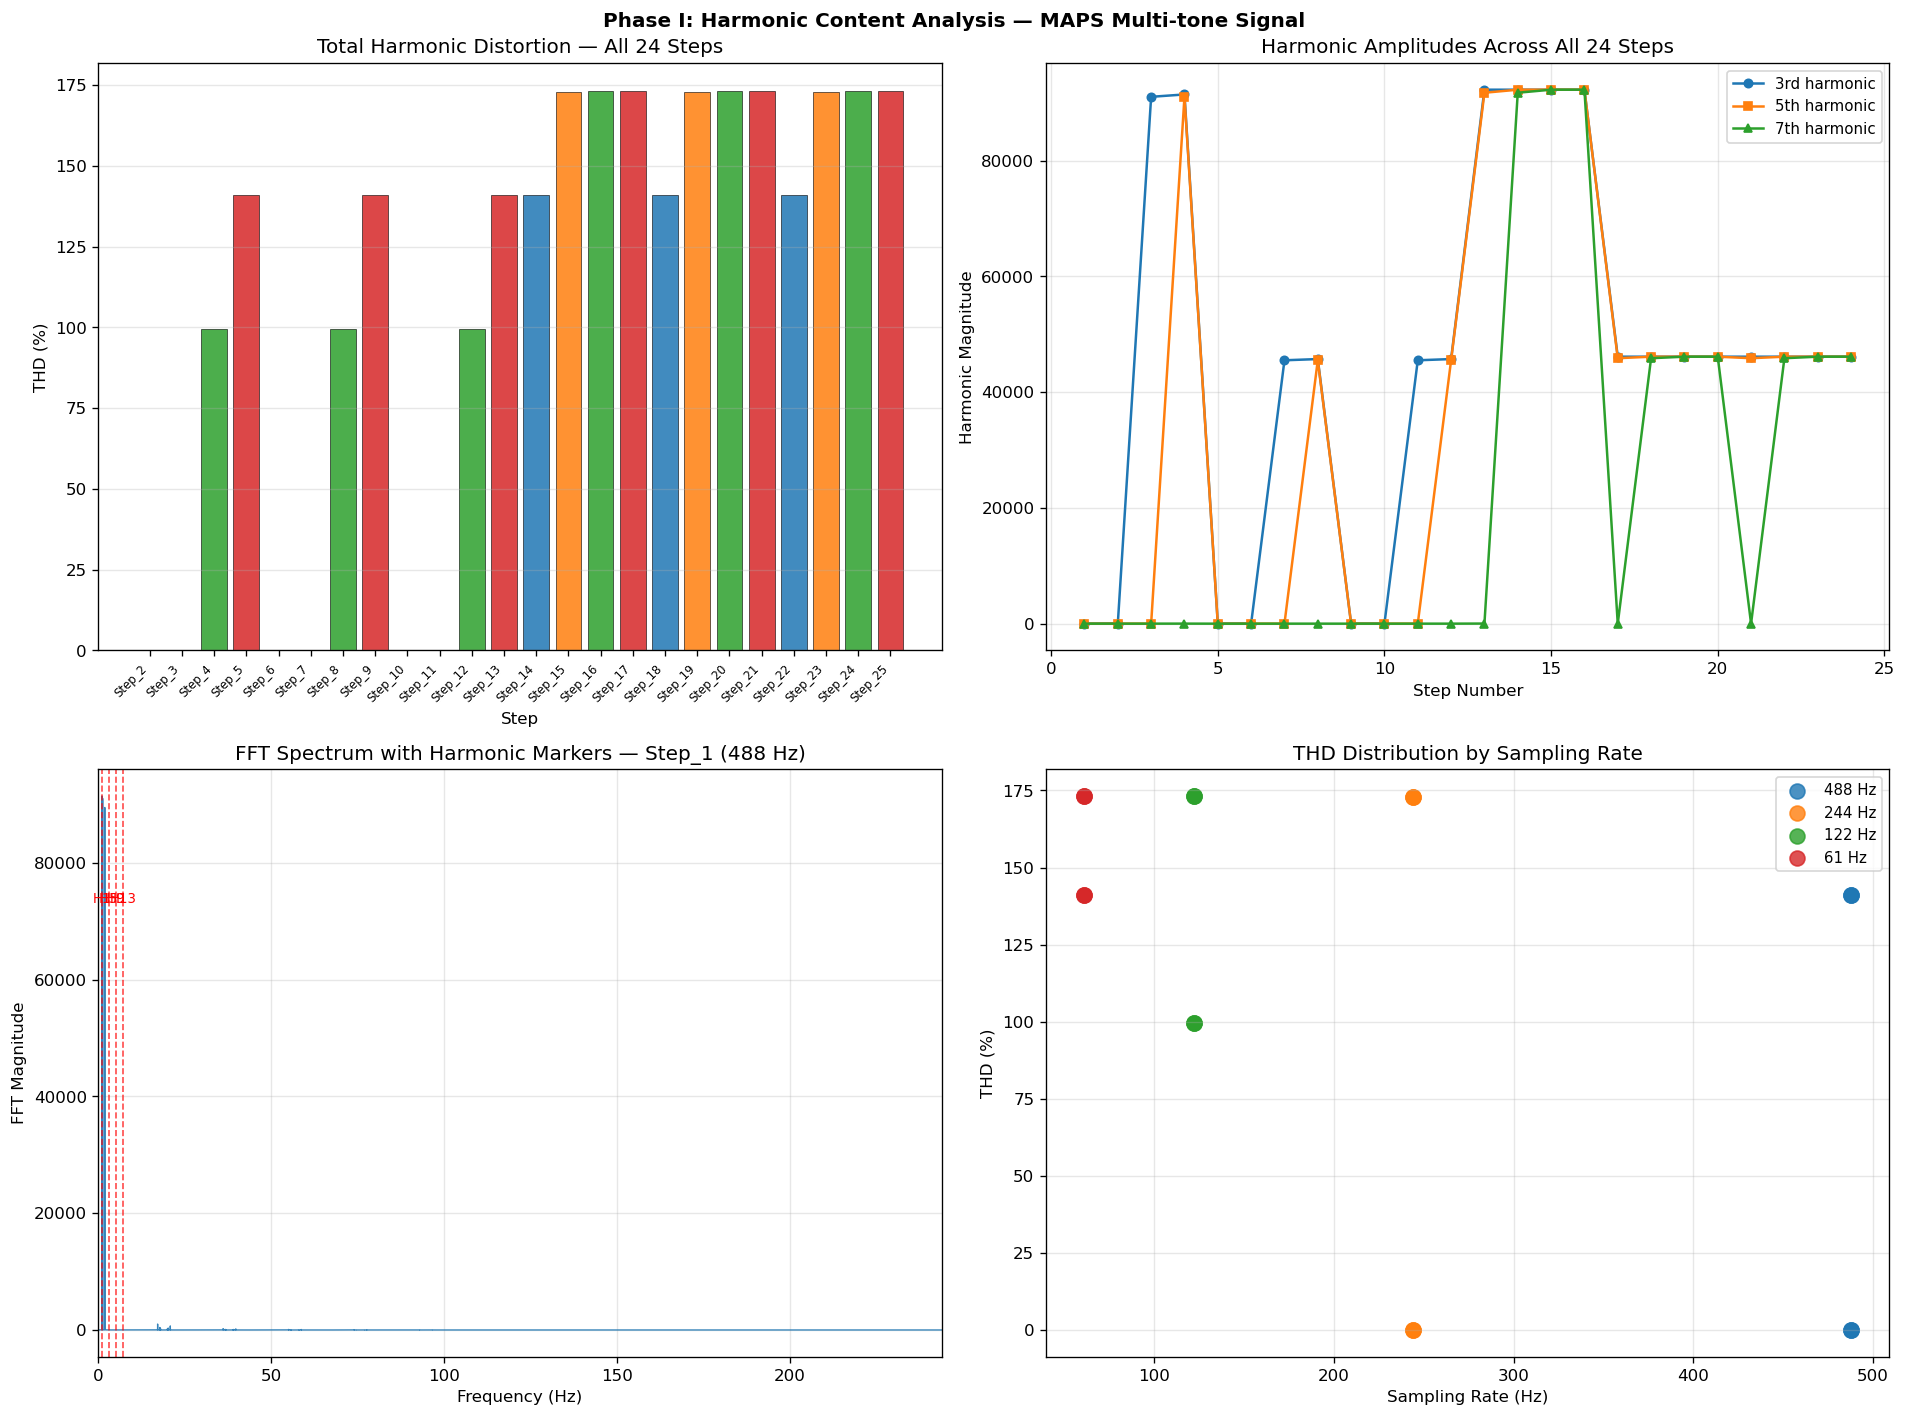

In [22]:
# ==========================================
# CELL I2: Harmonic Visualisation
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
color_by_rate = {488: '#1f77b4', 244: '#ff7f0e', 122: '#2ca02c', 61: '#d62728'}

# THD per step
ax1 = axes[0, 0]
bar_colors = [color_by_rate.get(r, 'gray') for r in harmonic_df['Sampling_Hz']]
ax1.bar(harmonic_df['Step'], harmonic_df['THD_pct'], color=bar_colors, alpha=0.85, edgecolor='black', linewidth=0.4)
ax1.set_xlabel("Step")
ax1.set_ylabel("THD (%)")
ax1.set_title("Total Harmonic Distortion — All 24 Steps")
ax1.set_xticklabels(harmonic_df['Step'], rotation=45, ha='right', fontsize=7)
ax1.grid(True, alpha=0.3, axis='y')

# Harmonic magnitudes
ax2 = axes[0, 1]
step_numbers = range(1, len(harmonic_df) + 1)
ax2.plot(step_numbers, harmonic_df['Mag_3rd'], 'o-', linewidth=1.5, markersize=5, label='3rd harmonic')
ax2.plot(step_numbers, harmonic_df['Mag_5th'], 's-', linewidth=1.5, markersize=5, label='5th harmonic')
ax2.plot(step_numbers, harmonic_df['Mag_7th'], '^-', linewidth=1.5, markersize=5, label='7th harmonic')
ax2.set_xlabel("Step Number")
ax2.set_ylabel("Harmonic Magnitude")
ax2.set_title("Harmonic Amplitudes Across All 24 Steps")
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

# FFT with harmonic markers for Step_1
ax3 = axes[1, 0]
fft_step1 = fft_results_dictionary['Step_2']
ax3.plot(fft_step1['frequencies'], fft_step1['magnitudes'], linewidth=0.8, alpha=0.9)
fund_freq = fft_step1['frequencies'][np.argmax(fft_step1['magnitudes'])]
for h_num, h_mult in enumerate([1, 3, 5, 7], start=1):
    ax3.axvline(x=h_mult * fund_freq, color='red', linestyle='--', linewidth=1.0, alpha=0.7)
    ax3.text(h_mult * fund_freq, np.max(fft_step1['magnitudes']) * 0.8,
             f"H{h_mult * 2 - 1}" if h_num > 1 else "H1", fontsize=8, color='red', ha='center')
ax3.set_xlabel("Frequency (Hz)")
ax3.set_ylabel("FFT Magnitude")
ax3.set_title("FFT Spectrum with Harmonic Markers — Step_1 (488 Hz)")
ax3.set_xlim(0, 244)
ax3.grid(True, alpha=0.3)

# THD by sampling rate
ax4 = axes[1, 1]
for rate in [488, 244, 122, 61]:
    rate_data = harmonic_df[harmonic_df['Sampling_Hz'] == rate]
    ax4.scatter([rate] * len(rate_data), rate_data['THD_pct'],
                s=80, color=color_by_rate.get(rate, 'gray'), alpha=0.8, label=f"{rate} Hz")
ax4.set_xlabel("Sampling Rate (Hz)")
ax4.set_ylabel("THD (%)")
ax4.set_title("THD Distribution by Sampling Rate")
ax4.legend(fontsize=9)
ax4.grid(True, alpha=0.3)

plt.suptitle("Phase I: Harmonic Content Analysis — MAPS Multi-tone Signal", fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE J — Instantaneous Signal Features

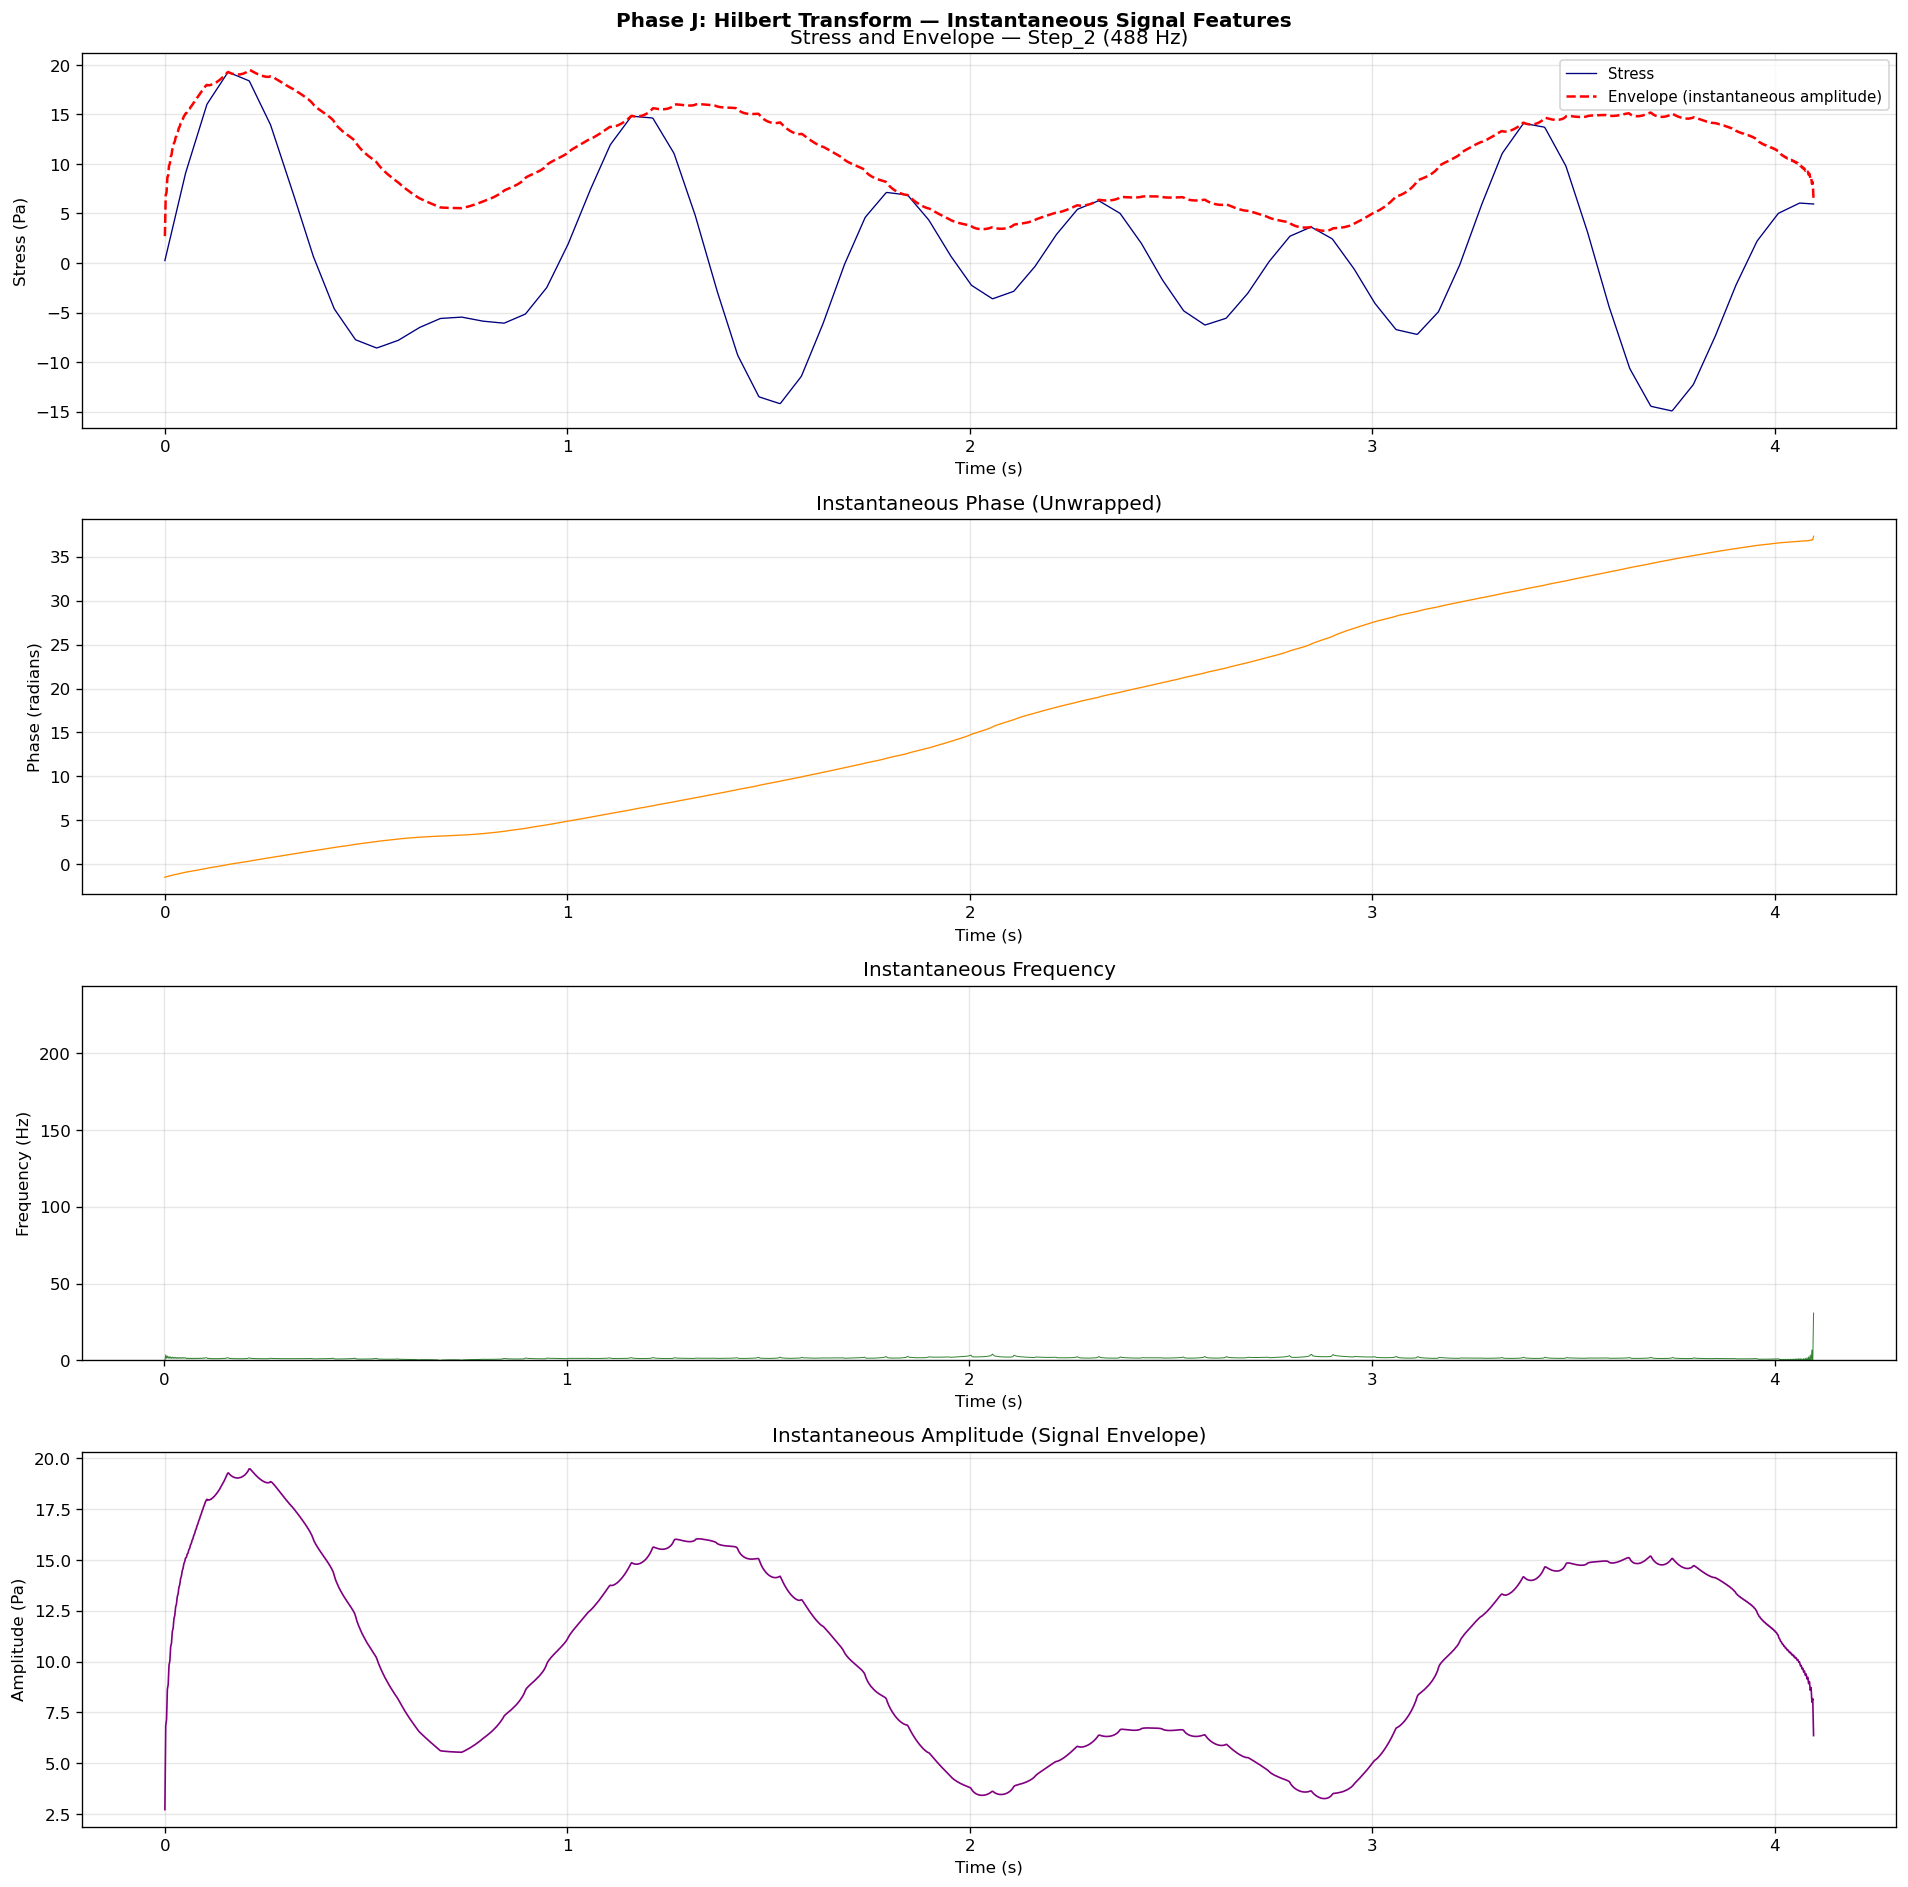

Mean instantaneous frequency: 1.508 Hz
Std instantaneous frequency:  0.865 Hz
Mean envelope amplitude:      10.371484 Pa


In [23]:
# ==========================================
# CELL J1: Hilbert Transform — Instantaneous Features
# ==========================================

from scipy.signal import hilbert

reference_step    = 'Step_2'
sampling_rate_ref = 488
n_points_hilbert  = 2000
stress_segment    = maps_steps_dictionary[reference_step]['stress_Pa'].values[:n_points_hilbert]
time_segment      = np.arange(n_points_hilbert) / sampling_rate_ref

analytic_signal         = hilbert(stress_segment)
instantaneous_amplitude = np.abs(analytic_signal)
instantaneous_phase     = np.unwrap(np.angle(analytic_signal))
instantaneous_frequency = np.diff(instantaneous_phase) / (2.0 * np.pi * (1.0 / sampling_rate_ref))

fig, axes = plt.subplots(4, 1, figsize=(16, 16))

axes[0].plot(time_segment, stress_segment, linewidth=0.8, color='navy', label='Stress')
axes[0].plot(time_segment, instantaneous_amplitude, linewidth=1.5, color='red',
             linestyle='--', label='Envelope (instantaneous amplitude)')
axes[0].set_title(f"Stress and Envelope — {reference_step} ({sampling_rate_ref} Hz)")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Stress (Pa)")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_segment, instantaneous_phase, linewidth=0.8, color='darkorange')
axes[1].set_title("Instantaneous Phase (Unwrapped)")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Phase (radians)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_segment[1:], instantaneous_frequency, linewidth=0.6, color='darkgreen', alpha=0.8)
axes[2].set_title("Instantaneous Frequency")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Frequency (Hz)")
axes[2].set_ylim(0, sampling_rate_ref / 2)
axes[2].grid(True, alpha=0.3)

axes[3].plot(time_segment, instantaneous_amplitude, linewidth=1.0, color='purple')
axes[3].set_title("Instantaneous Amplitude (Signal Envelope)")
axes[3].set_xlabel("Time (s)")
axes[3].set_ylabel("Amplitude (Pa)")
axes[3].grid(True, alpha=0.3)

plt.suptitle("Phase J: Hilbert Transform — Instantaneous Signal Features", fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Mean instantaneous frequency: {np.mean(instantaneous_frequency):.3f} Hz")
print(f"Std instantaneous frequency:  {np.std(instantaneous_frequency):.3f} Hz")
print(f"Mean envelope amplitude:      {np.mean(instantaneous_amplitude):.6f} Pa")

## PHASE K — Viscoelastic Characterisation from SAOS

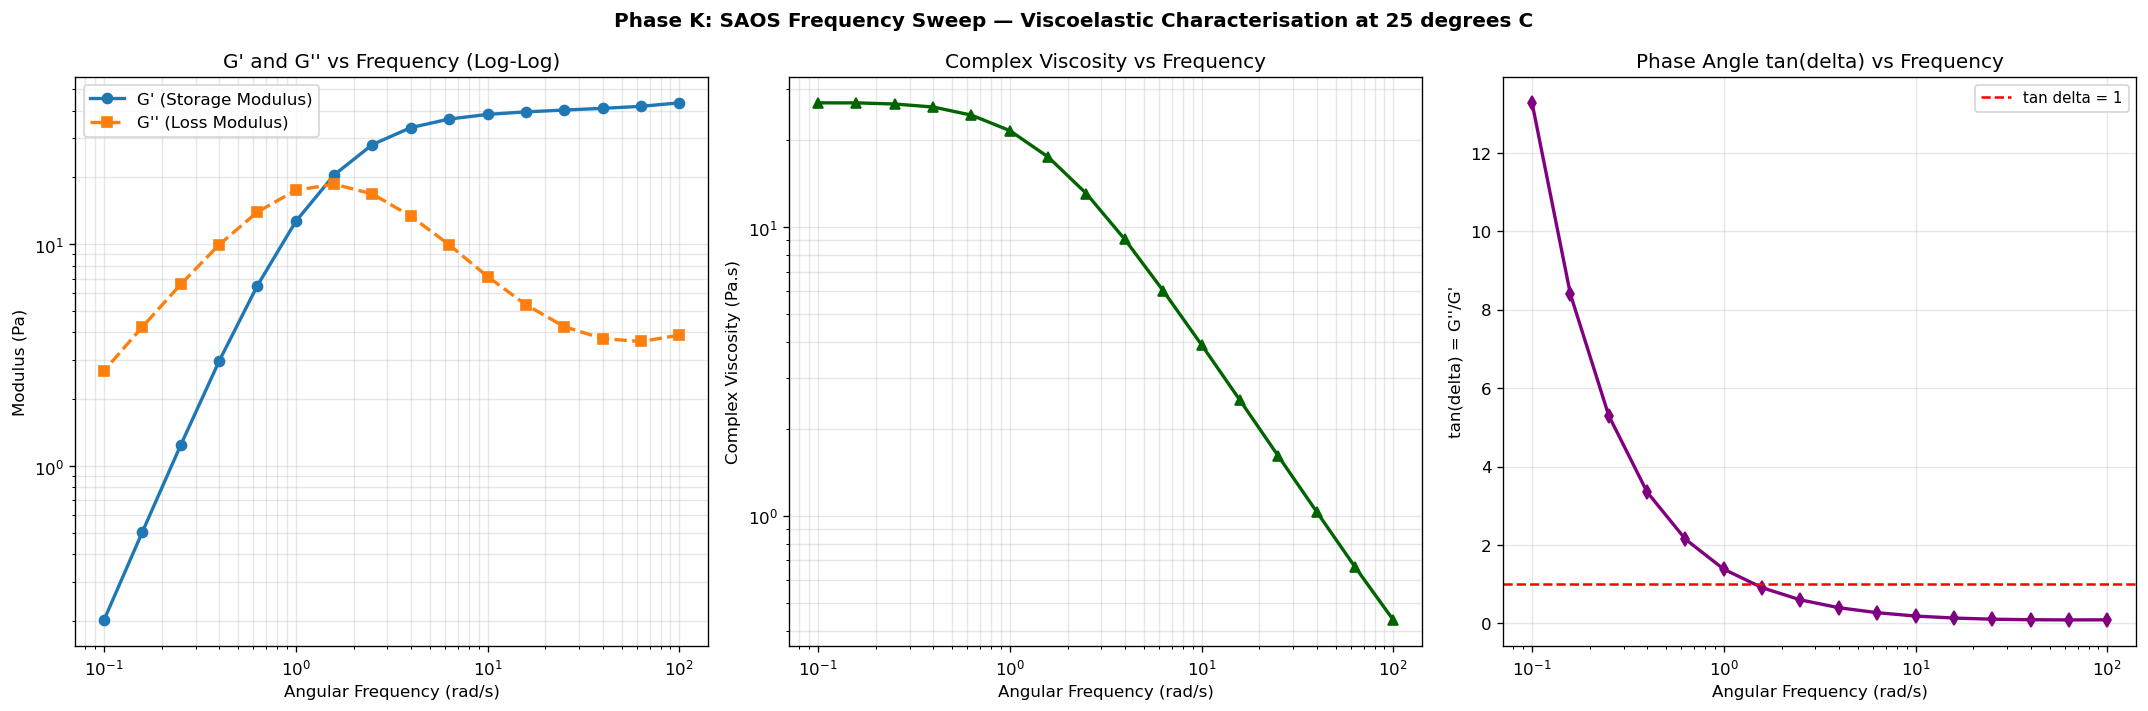

SAOS KEY VISCOELASTIC PARAMETERS
Frequency range:      0.100 to 100.0 rad/s
G' range:             0.202 to 43.371 Pa
G'' range:            2.688 to 18.655 Pa
Complex viscosity:    0.435 to 26.953 Pa.s
tan(delta) range:     0.0871 to 13.2824
Material state:       SOL (G'' > G') at highest frequency


In [24]:
# ==========================================
# CELL K1: SAOS Frequency Sweep Analysis
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].loglog(saos_df['angular_freq_rad_s'], saos_df['storage_modulus_Pa'],
               'o-', linewidth=2, markersize=6, label="G' (Storage Modulus)")
axes[0].loglog(saos_df['angular_freq_rad_s'], saos_df['loss_modulus_Pa'],
               's--', linewidth=2, markersize=6, label="G'' (Loss Modulus)")
axes[0].set_xlabel("Angular Frequency (rad/s)")
axes[0].set_ylabel("Modulus (Pa)")
axes[0].set_title("G' and G'' vs Frequency (Log-Log)")
axes[0].legend(fontsize=10)
axes[0].grid(True, which='both', alpha=0.3)

axes[1].loglog(saos_df['angular_freq_rad_s'], saos_df['complex_viscosity_Pa_s'],
               '^-', linewidth=2, markersize=6, color='darkgreen')
axes[1].set_xlabel("Angular Frequency (rad/s)")
axes[1].set_ylabel("Complex Viscosity (Pa.s)")
axes[1].set_title("Complex Viscosity vs Frequency")
axes[1].grid(True, which='both', alpha=0.3)

axes[2].semilogx(saos_df['angular_freq_rad_s'], saos_df['tan_delta'],
                 'd-', linewidth=2, markersize=6, color='purple')
axes[2].axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, label='tan delta = 1')
axes[2].set_xlabel("Angular Frequency (rad/s)")
axes[2].set_ylabel("tan(delta) = G''/G'")
axes[2].set_title("Phase Angle tan(delta) vs Frequency")
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.suptitle("Phase K: SAOS Frequency Sweep — Viscoelastic Characterisation at 25 degrees C",
             fontweight='bold')
plt.tight_layout()
plt.show()

print("=" * 60)
print("SAOS KEY VISCOELASTIC PARAMETERS")
print("=" * 60)
print(f"Frequency range:      {saos_df['angular_freq_rad_s'].min():.3f} to {saos_df['angular_freq_rad_s'].max():.1f} rad/s")
print(f"G' range:             {saos_df['storage_modulus_Pa'].min():.3f} to {saos_df['storage_modulus_Pa'].max():.3f} Pa")
print(f"G'' range:            {saos_df['loss_modulus_Pa'].min():.3f} to {saos_df['loss_modulus_Pa'].max():.3f} Pa")
print(f"Complex viscosity:    {saos_df['complex_viscosity_Pa_s'].min():.3f} to {saos_df['complex_viscosity_Pa_s'].max():.3f} Pa.s")
print(f"tan(delta) range:     {saos_df['tan_delta'].min():.4f} to {saos_df['tan_delta'].max():.4f}")
final_state = "GEL (G' > G'')" if saos_df['storage_modulus_Pa'].iloc[-1] > saos_df['loss_modulus_Pa'].iloc[-1] else "SOL (G'' > G')"
print(f"Material state:       {final_state} at highest frequency")

POWER LAW FITTING — RELAXATION SPECTRUM ANALYSIS
G'(omega)  ~ omega^n:  n = 0.7023  (R-squared = 0.7660)
G''(omega) ~ omega^m:  m = -0.0754  (R-squared = 0.0647)

Material interpretation: Gel-like (weak power law)


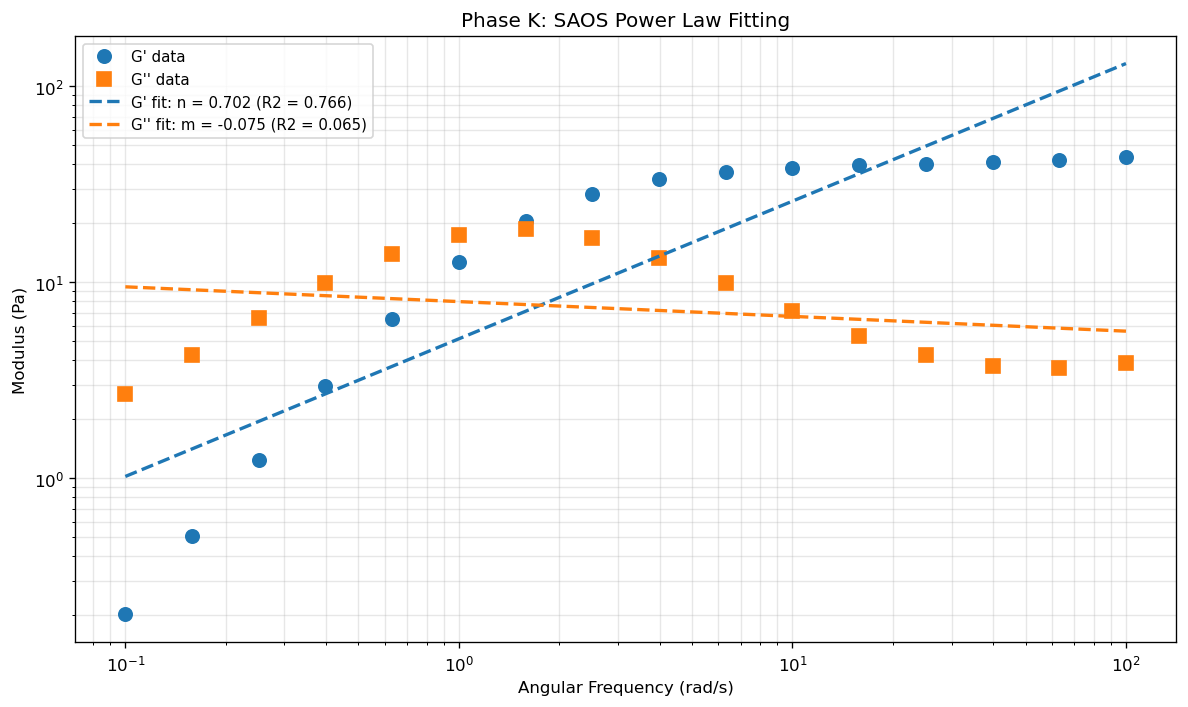

In [25]:
# ==========================================
# CELL K2: Power Law Fitting — Relaxation Spectrum
# ==========================================

valid_saos = saos_df[saos_df['storage_modulus_Pa'] > 0].copy()
log_omega    = np.log(valid_saos['angular_freq_rad_s'].values)
log_G_prime  = np.log(valid_saos['storage_modulus_Pa'].values)
log_G_double = np.log(valid_saos['loss_modulus_Pa'].values)

slope_G_prime,  intercept_Gp,  r_Gp,  _, _ = stats.linregress(log_omega, log_G_prime)
slope_G_double, intercept_Gpp, r_Gpp, _, _ = stats.linregress(log_omega, log_G_double)

print("=" * 60)
print("POWER LAW FITTING — RELAXATION SPECTRUM ANALYSIS")
print("=" * 60)
print(f"G'(omega)  ~ omega^n:  n = {slope_G_prime:.4f}  (R-squared = {r_Gp**2:.4f})")
print(f"G''(omega) ~ omega^m:  m = {slope_G_double:.4f}  (R-squared = {r_Gpp**2:.4f})")
print()
if slope_G_prime > 1.8:
    material_state = "Liquid-like (Newtonian limit: G' ~ omega^2)"
elif slope_G_prime > 0.9:
    material_state = "Transitioning viscoelastic fluid"
elif slope_G_prime > 0.3:
    material_state = "Gel-like (weak power law)"
else:
    material_state = "Solid-like (near-elastic)"
print(f"Material interpretation: {material_state}")

omega_fit    = np.logspace(np.log10(saos_df['angular_freq_rad_s'].min()),
                            np.log10(saos_df['angular_freq_rad_s'].max()), 100)
G_prime_fit  = np.exp(intercept_Gp)  * omega_fit ** slope_G_prime
G_double_fit = np.exp(intercept_Gpp) * omega_fit ** slope_G_double

fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(saos_df['angular_freq_rad_s'], saos_df['storage_modulus_Pa'],
          'o', markersize=8, color='#1f77b4', label="G' data")
ax.loglog(saos_df['angular_freq_rad_s'], saos_df['loss_modulus_Pa'],
          's', markersize=8, color='#ff7f0e', label="G'' data")
ax.loglog(omega_fit, G_prime_fit, '--', linewidth=2, color='#1f77b4',
          label=f"G' fit: n = {slope_G_prime:.3f} (R2 = {r_Gp**2:.3f})")
ax.loglog(omega_fit, G_double_fit, '--', linewidth=2, color='#ff7f0e',
          label=f"G'' fit: m = {slope_G_double:.3f} (R2 = {r_Gpp**2:.3f})")
ax.set_xlabel("Angular Frequency (rad/s)")
ax.set_ylabel("Modulus (Pa)")
ax.set_title("Phase K: SAOS Power Law Fitting")
ax.legend(fontsize=9)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

## PHASE O — Feature Stability and Robustness

In [26]:
# ==========================================
# CELL O1: Reproducibility Across Steps at Same Sampling Rate
# ==========================================

print("=" * 80)
print("REPRODUCIBILITY — CONSISTENCY ACROSS STEPS AT SAME SAMPLING RATE")
print("=" * 80)

for sampling_rate in [488, 244, 122, 61]:
    rate_data = harmonic_df[harmonic_df['Sampling_Hz'] == sampling_rate]
    if len(rate_data) == 0:
        continue
    fund_freqs = rate_data['Fundamental_Hz'].values
    thd_values = rate_data['THD_pct'].values
    snr_subset = snr_df[snr_df['Sampling_Hz'] == sampling_rate]['SNR_dB'].values
    cv_fund    = (np.std(fund_freqs) / np.mean(fund_freqs) * 100) if np.mean(fund_freqs) > 0 else 0
    cv_thd     = (np.std(thd_values) / np.mean(thd_values) * 100) if np.mean(thd_values) > 0 else 0
    assessment = "Good (CV < 10%)" if cv_fund < 10 else ("Acceptable (CV < 20%)" if cv_fund < 20 else "High variability")
    print(f"\nSampling Rate {sampling_rate} Hz ({len(rate_data)} steps):")
    print(f"  Dominant Freq: mean = {np.mean(fund_freqs):.4f} Hz | std = {np.std(fund_freqs):.4f} | CV = {cv_fund:.1f}%")
    print(f"  THD:           mean = {np.mean(thd_values):.3f}%   | std = {np.std(thd_values):.3f} | CV = {cv_thd:.1f}%")
    print(f"  SNR:           mean = {np.mean(snr_subset):.2f} dB  | std = {np.std(snr_subset):.2f}")
    print(f"  Reproducibility: {assessment}")

REPRODUCIBILITY — CONSISTENCY ACROSS STEPS AT SAME SAMPLING RATE

Sampling Rate 488 Hz (6 steps):
  Dominant Freq: mean = 0.6108 Hz | std = 0.4072 | CV = 66.7%
  THD:           mean = 70.518%   | std = 70.501 | CV = 100.0%
  SNR:           mean = 109.34 dB  | std = 0.10
  Reproducibility: High variability

Sampling Rate 244 Hz (6 steps):
  Dominant Freq: mean = 0.3054 Hz | std = 0.2036 | CV = 66.7%
  THD:           mean = 86.455%   | std = 86.422 | CV = 100.0%
  SNR:           mean = 109.34 dB  | std = 0.08
  Reproducibility: High variability

Sampling Rate 122 Hz (6 steps):
  Dominant Freq: mean = 0.1527 Hz | std = 0.1018 | CV = 66.7%
  THD:           mean = 136.367%   | std = 36.838 | CV = 27.0%
  SNR:           mean = 114.42 dB  | std = 7.23
  Reproducibility: High variability

Sampling Rate 61 Hz (6 steps):
  Dominant Freq: mean = 0.0763 Hz | std = 0.0509 | CV = 66.7%
  THD:           mean = 157.156%   | std = 16.049 | CV = 10.2%
  SNR:           mean = 109.32 dB  | std = 0.07
  Re

In [27]:
# ==========================================
# CELL O2: Noise Sensitivity Analysis
# ==========================================

reference_step    = 'Step_2'
reference_signal  = maps_steps_dictionary[reference_step]['stress_Pa'].values[:2000]
sampling_rate_ref = 488
noise_levels      = [0.001, 0.01, 0.05, 0.1, 0.2]

print("=" * 65)
print("NOISE SENSITIVITY — STEP_1 (488 Hz), FIRST 2000 SAMPLES")
print("=" * 65)
print(f"{'Noise Level':>12} {'SNR (dB)':>10} {'Dominant Freq (Hz)':>20} {'Assessment':>15}")
print("-" * 62)

noise_sensitivity_records = []
for noise_level in noise_levels:
    np.random.seed(42)
    noisy_signal = reference_signal + noise_level * np.std(reference_signal) * np.random.randn(len(reference_signal))
    fft_noisy_snr   = np.abs(np.fft.fft(noisy_signal))
    peak_mag_noisy  = np.max(fft_noisy_snr[:len(fft_noisy_snr)//2])
    median_mag_noisy = np.median(fft_noisy_snr[:len(fft_noisy_snr)//2])
    snr_db_noisy    = 20.0 * np.log10(peak_mag_noisy / (median_mag_noisy + 1e-12))
    fft_noisy    = np.abs(np.fft.fft(noisy_signal))
    freq_bins    = np.fft.fftfreq(len(noisy_signal), d=1.0 / sampling_rate_ref)
    positive_mask = freq_bins > 0
    dominant_freq_noisy = freq_bins[positive_mask][np.argmax(fft_noisy[positive_mask])]
    assessment = "Robust" if snr_db_noisy > 20 else ("Acceptable" if snr_db_noisy > 10 else "Degraded")
    noise_sensitivity_records.append({'Noise Level': noise_level, 'SNR (dB)': snr_db_noisy,
                                       'Dominant Freq': dominant_freq_noisy, 'Assessment': assessment})
    print(f"{noise_level:>12.3f} {snr_db_noisy:>10.2f} {dominant_freq_noisy:>20.4f} {assessment:>15}")

noise_sens_df = pd.DataFrame(noise_sensitivity_records)

NOISE SENSITIVITY — STEP_1 (488 Hz), FIRST 2000 SAMPLES
 Noise Level   SNR (dB)   Dominant Freq (Hz)      Assessment
--------------------------------------------------------------
       0.001      64.39               0.9760          Robust
       0.010      61.67               0.9760          Robust
       0.050      52.54               0.9760          Robust
       0.100      47.23               0.9760          Robust
       0.200      41.35               0.9760          Robust


## PHASE R — Algorithm Scoring System

In [28]:
# ==========================================
# CELL R1: Algorithm Comparison Table — Data 6
# ==========================================

print("=" * 100)
print("ALGORITHM COMPARISON TABLE — DATA 6 MITMAPS")
print("=" * 100)
print()

comparison_data = {
    'Criterion': [
        'Raw stress-strain available',
        'Sampling rate >= 100 Hz',
        'Broadband multi-frequency',
        'Frequency range 0.1-60 rad/s',
        'Stationarity (LTI) valid',
        'Harmonic detection',
        'Gel point detection',
        'Mutation number applicable',
        'Time-frequency resolution',
        'Computational efficiency',
        'FPGA implementable',
        'Published benchmark validation',
    ],
    'FFT': [
        'YES — 61-488 Hz raw signal',
        'YES — all steps meet requirement',
        'YES — MAPS designed for FFT',
        'YES — SAOS 0.1-100 rad/s',
        'YES — confirmed stationary',
        'YES — primary harmonic method',
        'NOT APPLICABLE',
        'NOT APPLICABLE',
        'Fixed (no time resolution)',
        'Very fast O(N log N)',
        'YES',
        'YES — MAPS and hermes-rheo papers',
    ],
    'STFT': [
        'YES', 'YES', 'YES', 'YES', 'YES',
        'YES — from time-localised spectrum',
        'NOT APPLICABLE', 'NOT APPLICABLE',
        'Fixed (Heisenberg limited)',
        'Fast O(N log N per window)',
        'YES', 'Partial',
    ],
    'CWT': [
        'YES', 'YES', 'YES', 'YES', 'YES',
        'YES — from scalogram energy',
        'NOT APPLICABLE', 'NOT APPLICABLE',
        'Adaptive (best of three)',
        'Moderate O(N * n_scales)',
        'Challenging',
        'YES — Torrence and Compo 1998',
    ]
}

comparison_df = pd.DataFrame(comparison_data).set_index('Criterion').T
print(comparison_df.to_string())

ALGORITHM COMPARISON TABLE — DATA 6 MITMAPS

Criterion Raw stress-strain available           Sampling rate >= 100 Hz    Broadband multi-frequency Frequency range 0.1-60 rad/s    Stationarity (LTI) valid                  Harmonic detection Gel point detection Mutation number applicable   Time-frequency resolution    Computational efficiency FPGA implementable     Published benchmark validation
FFT        YES — 61-488 Hz raw signal  YES — all steps meet requirement  YES — MAPS designed for FFT     YES — SAOS 0.1-100 rad/s  YES — confirmed stationary       YES — primary harmonic method      NOT APPLICABLE             NOT APPLICABLE  Fixed (no time resolution)        Very fast O(N log N)                YES  YES — MAPS and hermes-rheo papers
STFT                              YES                               YES                          YES                          YES                         YES  YES — from time-localised spectrum      NOT APPLICABLE             NOT APPLICABLE  Fixed (Heis

In [29]:
# ==========================================
# CELL R2: Quantitative Scoring Matrix — Data 6
# ==========================================

scoring_criteria = [
    'Harmonic detection accuracy',
    'Frequency resolution',
    'Time resolution',
    'Stationary signal handling',
    'Noise robustness',
    'Computational efficiency',
    'FPGA implementable',
    'Broadband coverage',
]
scoring_values = {'FFT': [5, 5, 1, 5, 4, 5, 5, 5],
                  'STFT': [4, 3, 3, 4, 3, 4, 4, 4],
                  'CWT': [4, 4, 5, 4, 4, 3, 2, 5]}
scoring_weights = {
    'Harmonic detection accuracy': 0.25,
    'Frequency resolution': 0.15,
    'Time resolution': 0.10,
    'Stationary signal handling': 0.15,
    'Noise robustness': 0.15,
    'Computational efficiency': 0.10,
    'FPGA implementable': 0.05,
    'Broadband coverage': 0.05,
}

print("=" * 65)
print("QUANTITATIVE SCORING MATRIX (1 = Poor, 5 = Excellent)")
print("=" * 65)
print(f"{'Criterion':<30} {'Weight':>8} {'FFT':>6} {'STFT':>6} {'CWT':>6}")
print("-" * 60)

weighted_totals = {'FFT': 0.0, 'STFT': 0.0, 'CWT': 0.0}
for idx, criterion in enumerate(scoring_criteria):
    weight = scoring_weights[criterion]
    for method in ['FFT', 'STFT', 'CWT']:
        weighted_totals[method] += weight * scoring_values[method][idx]
    print(f"{criterion:<30} {weight:>8.2f} {scoring_values['FFT'][idx]:>6} {scoring_values['STFT'][idx]:>6} {scoring_values['CWT'][idx]:>6}")

print("-" * 60)
print(f"{'WEIGHTED TOTAL':<30} {'1.00':>8} {weighted_totals['FFT']:>6.2f} {weighted_totals['STFT']:>6.2f} {weighted_totals['CWT']:>6.2f}")
winner = max(weighted_totals, key=weighted_totals.get)
print(f"\nHighest scoring on Data 6: {winner} ({weighted_totals[winner]:.2f}/5.00)")
print("FFT leads on Data 6 — stationary broadband signal is the ideal case for Fourier.")
print("CWT advantage (time resolution) matters more for non-stationary signals like Data 4.")

QUANTITATIVE SCORING MATRIX (1 = Poor, 5 = Excellent)
Criterion                        Weight    FFT   STFT    CWT
------------------------------------------------------------
Harmonic detection accuracy        0.25      5      4      4
Frequency resolution               0.15      5      3      4
Time resolution                    0.10      1      3      5
Stationary signal handling         0.15      5      4      4
Noise robustness                   0.15      4      3      4
Computational efficiency           0.10      5      4      3
FPGA implementable                 0.05      5      4      2
Broadband coverage                 0.05      5      4      5
------------------------------------------------------------
WEIGHTED TOTAL                     1.00   4.45   3.60   3.95

Highest scoring on Data 6: FFT (4.45/5.00)
FFT leads on Data 6 — stationary broadband signal is the ideal case for Fourier.
CWT advantage (time resolution) matters more for non-stationary signals like Data 4.


## PHASE S — Failure Mode Analysis

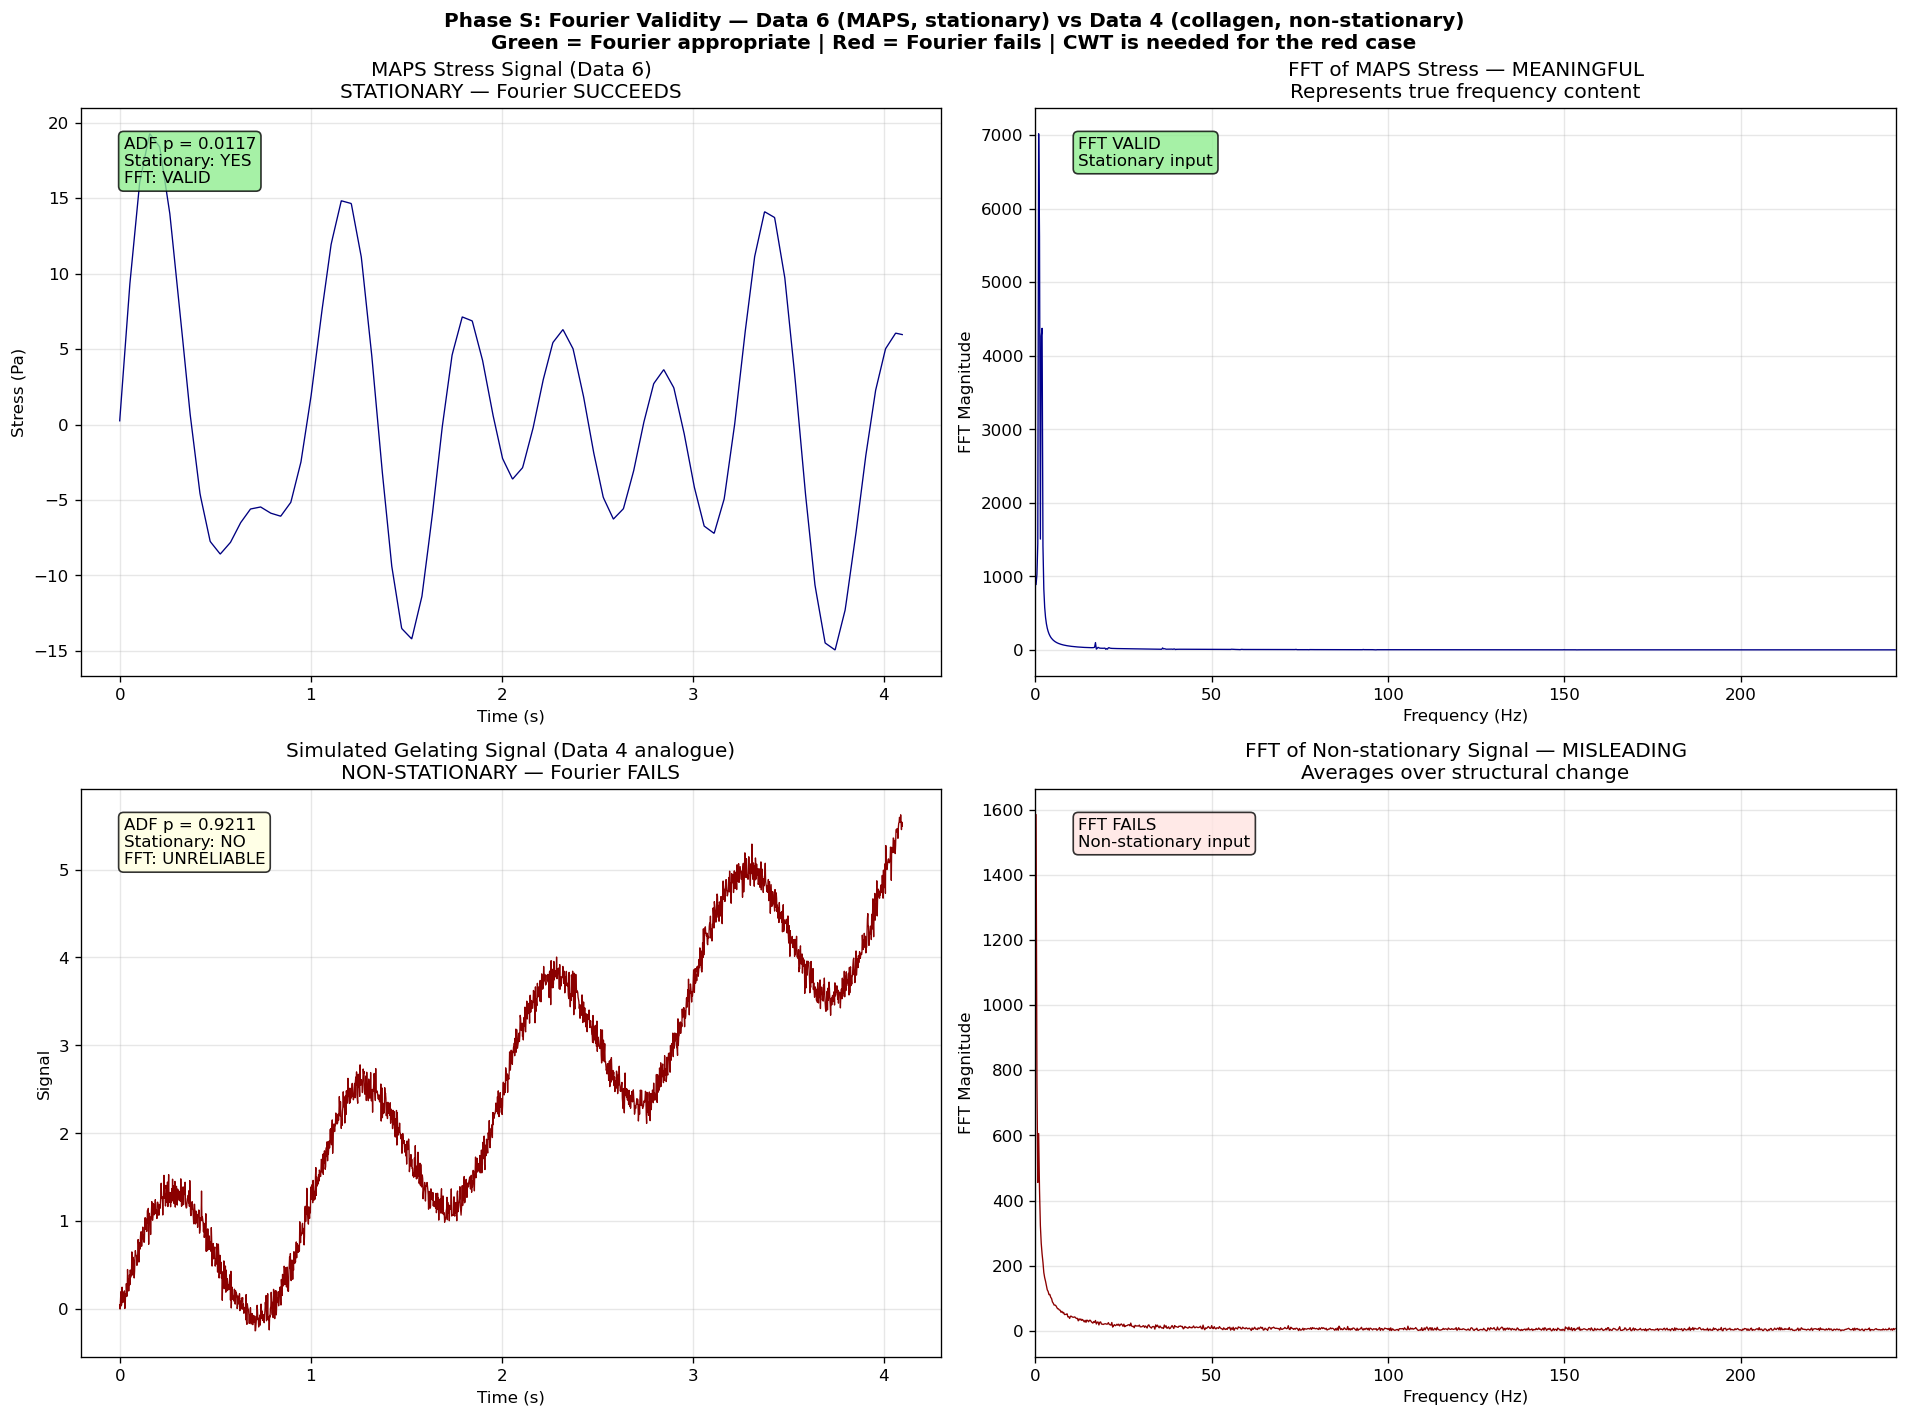

In [30]:
# ==========================================
# CELL S1: Fourier Succeeds Here — Contrast with Data 4
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

stress_step1 = maps_steps_dictionary['Step_2']['stress_Pa'].values[:2000]
time_step1   = np.arange(2000) / 488

# Stationary signal
axes[0, 0].plot(time_step1, stress_step1, linewidth=0.8, color='navy')
axes[0, 0].set_title("MAPS Stress Signal (Data 6)\nSTATIONARY — Fourier SUCCEEDS")
axes[0, 0].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Stress (Pa)")
axes[0, 0].grid(True, alpha=0.3)
adf_p = adfuller(stress_step1[::10], autolag='AIC')[1]
axes[0, 0].text(0.05, 0.95, f"ADF p = {adf_p:.4f}\nStationary: {'YES' if adf_p < 0.05 else 'NO'}\nFFT: VALID",
                transform=axes[0, 0].transAxes, fontsize=10, va='top',
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))

# FFT of stationary signal — meaningful
fft_step1  = np.abs(np.fft.fft(stress_step1))
freq_step1 = np.fft.fftfreq(len(stress_step1), d=1.0 / 488)
pos_mask   = freq_step1 > 0
axes[0, 1].plot(freq_step1[pos_mask], fft_step1[pos_mask], linewidth=0.8, color='darkblue')
axes[0, 1].set_title("FFT of MAPS Stress — MEANINGFUL\nRepresents true frequency content")
axes[0, 1].set_xlabel("Frequency (Hz)")
axes[0, 1].set_ylabel("FFT Magnitude")
axes[0, 1].set_xlim(0, 244)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].text(0.05, 0.95, "FFT VALID\nStationary input",
                transform=axes[0, 1].transAxes, fontsize=10, va='top',
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))

# Simulated gelation — non-stationary
n_sim = 2000
np.random.seed(42)
sim_gelation = np.sin(2 * np.pi * 1.0 * np.arange(n_sim) / 488)
sim_gelation += np.linspace(0, 5, n_sim)
sim_gelation += 0.1 * np.random.randn(n_sim)
time_sim = np.arange(n_sim) / 488

axes[1, 0].plot(time_sim, sim_gelation, linewidth=0.8, color='darkred')
axes[1, 0].set_title("Simulated Gelating Signal (Data 4 analogue)\nNON-STATIONARY — Fourier FAILS")
axes[1, 0].set_xlabel("Time (s)")
axes[1, 0].set_ylabel("Signal")
axes[1, 0].grid(True, alpha=0.3)
adf_p_gel = adfuller(sim_gelation[::10], autolag='AIC')[1]
axes[1, 0].text(0.05, 0.95, f"ADF p = {adf_p_gel:.4f}\nStationary: {'YES' if adf_p_gel < 0.05 else 'NO'}\nFFT: UNRELIABLE",
                transform=axes[1, 0].transAxes, fontsize=10, va='top',
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

fft_gel  = np.abs(np.fft.fft(sim_gelation))
freq_gel = np.fft.fftfreq(len(sim_gelation), d=1.0 / 488)
pos_gel  = freq_gel > 0
axes[1, 1].plot(freq_gel[pos_gel], fft_gel[pos_gel], linewidth=0.8, color='darkred')
axes[1, 1].set_title("FFT of Non-stationary Signal — MISLEADING\nAverages over structural change")
axes[1, 1].set_xlabel("Frequency (Hz)")
axes[1, 1].set_ylabel("FFT Magnitude")
axes[1, 1].set_xlim(0, 244)
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].text(0.05, 0.95, "FFT FAILS\nNon-stationary input",
                transform=axes[1, 1].transAxes, fontsize=10, va='top',
                bbox=dict(boxstyle='round', facecolor='mistyrose', alpha=0.8))

plt.suptitle("Phase S: Fourier Validity — Data 6 (MAPS, stationary) vs Data 4 (collagen, non-stationary)\n"
             "Green = Fourier appropriate | Red = Fourier fails | CWT is needed for the red case",
             fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE V — Visualisation System and Master Summary

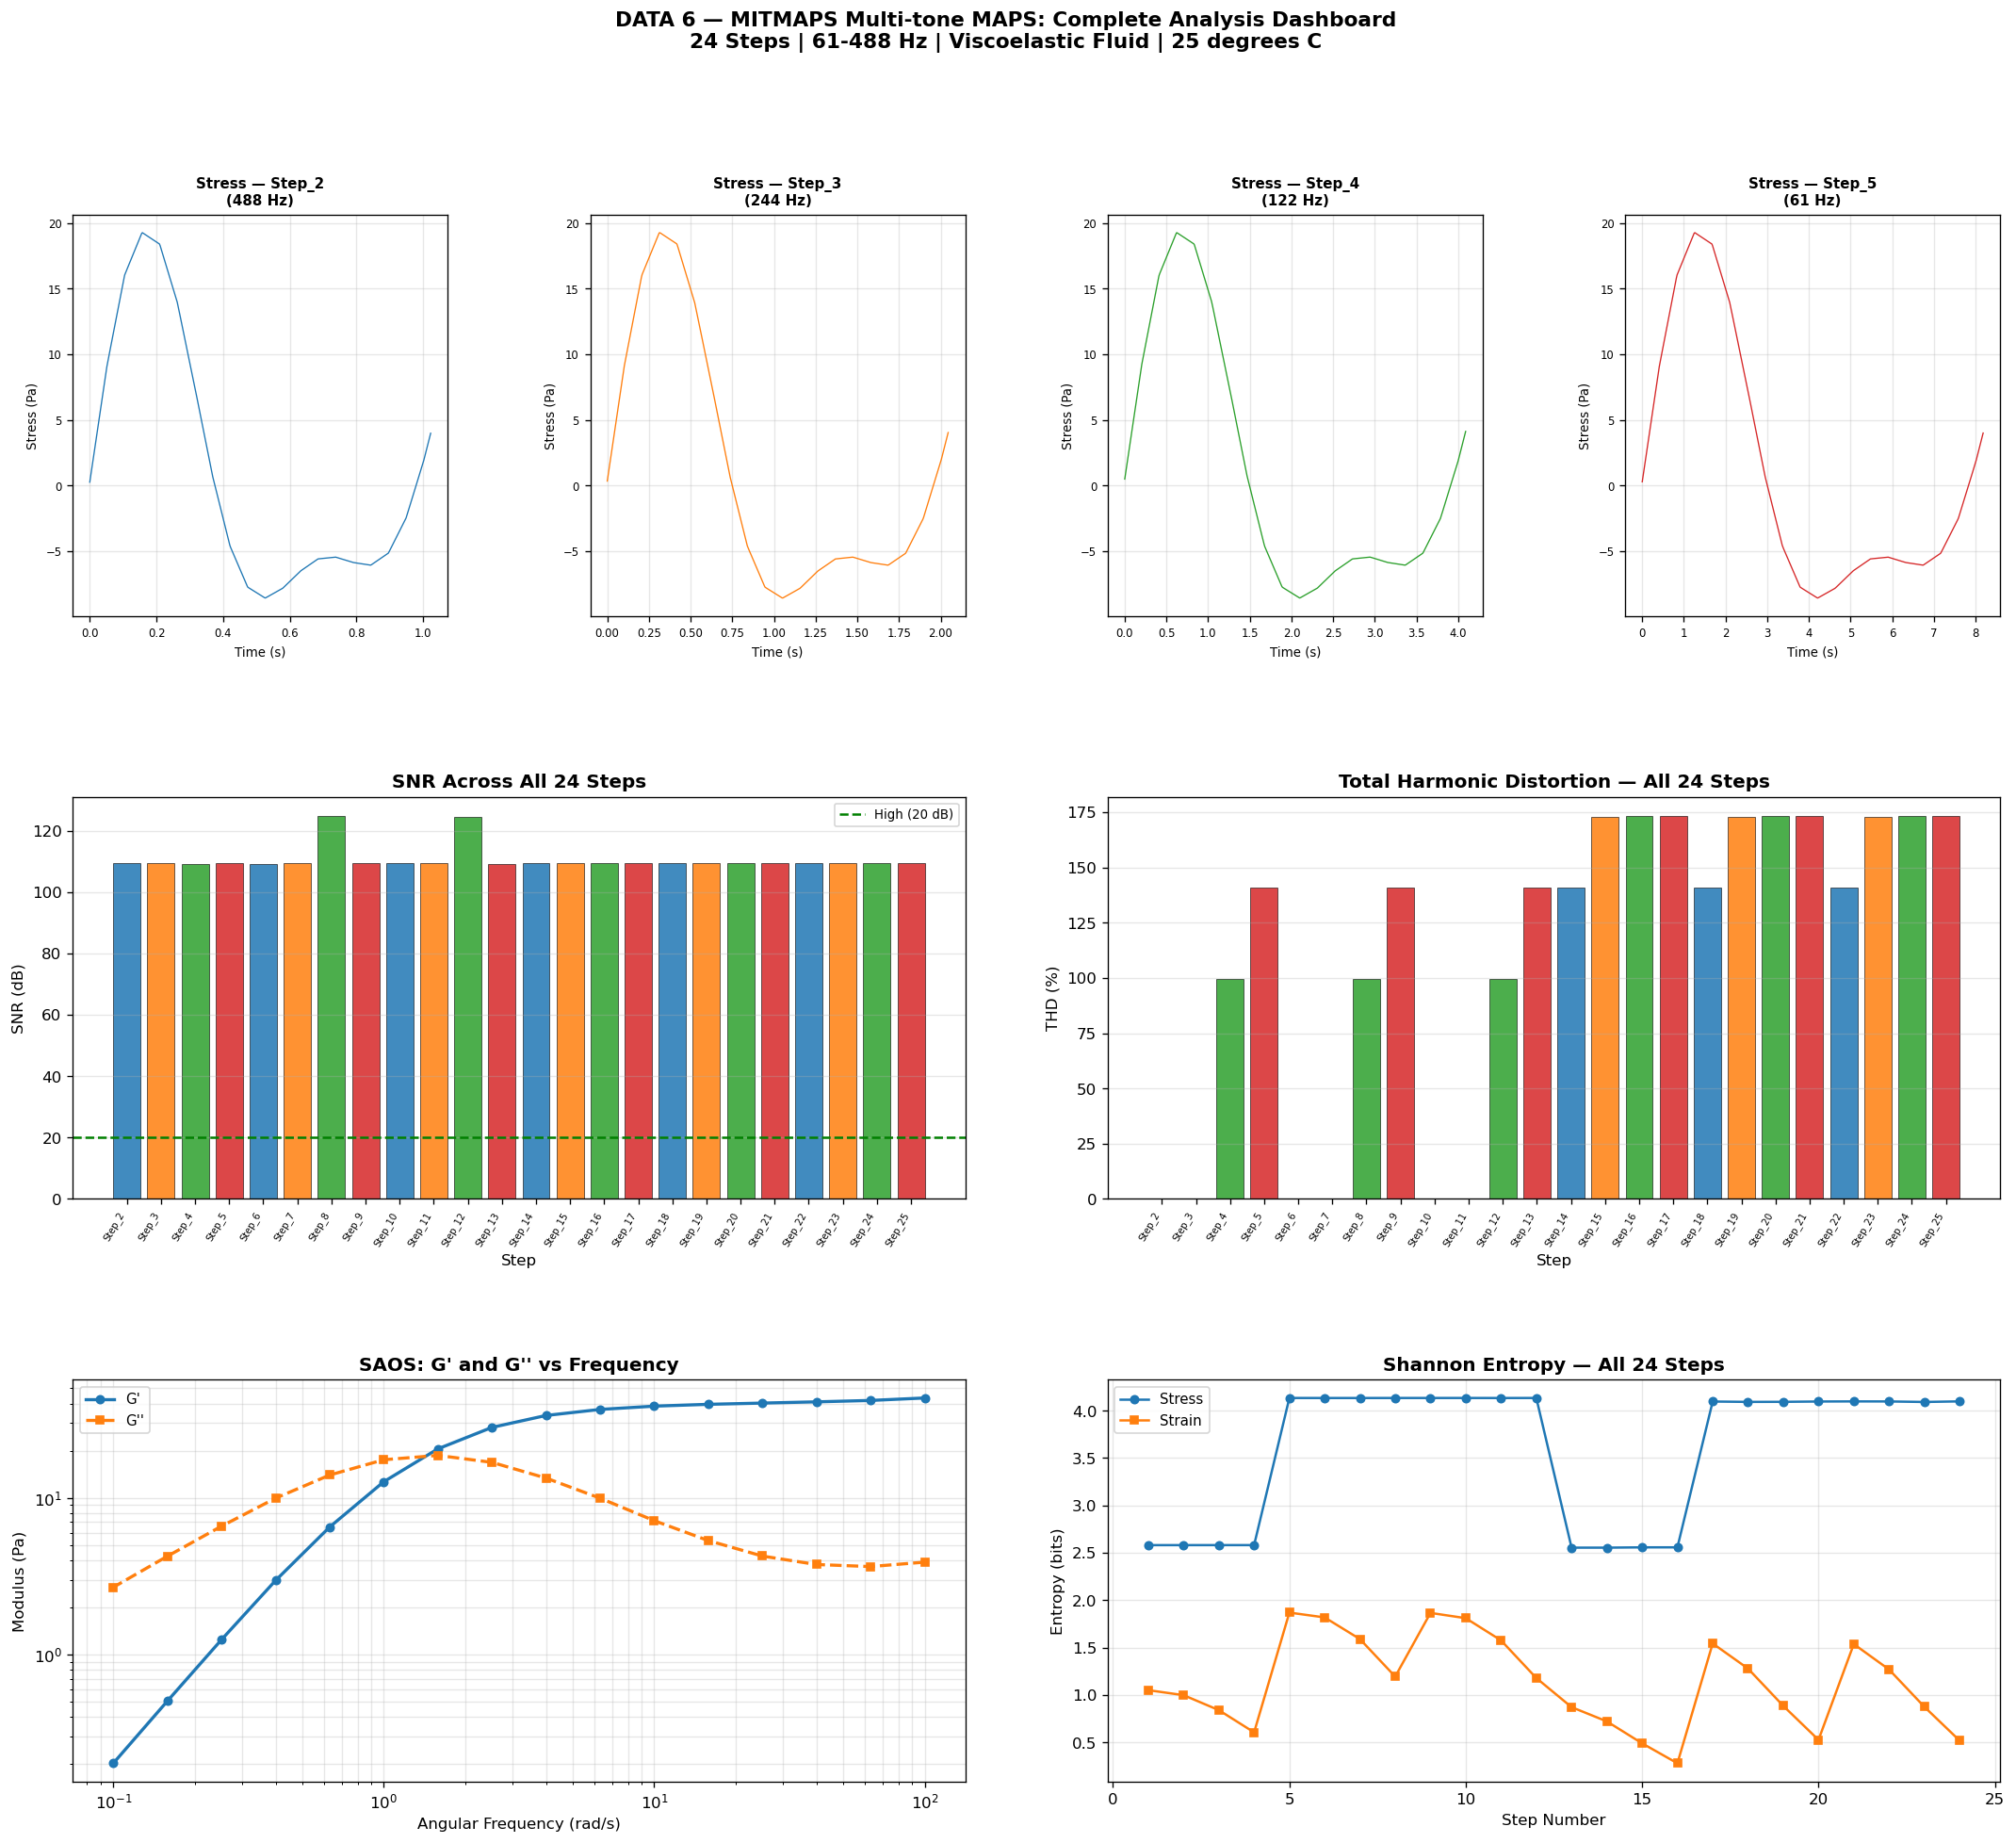

In [31]:
# ==========================================
# CELL V1: Master Dashboard — Data 6 MAPS
# ==========================================

fig = plt.figure(figsize=(22, 18))
grid_spec = gridspec.GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.38)
color_by_rate = {488: '#1f77b4', 244: '#ff7f0e', 122: '#2ca02c', 61: '#d62728'}

# Top row: Stress signals
for col_idx, (rate, sheet_name) in enumerate({488: 'Step_2', 244: 'Step_3', 122: 'Step_4', 61: 'Step_5'}.items()):
    ax = fig.add_subplot(grid_spec[0, col_idx])
    if sheet_name not in maps_steps_dictionary:
        continue
    signal = maps_steps_dictionary[sheet_name]['stress_Pa'].values[:500]
    time_s = np.arange(500) / rate
    ax.plot(time_s, signal, linewidth=0.8, color=color_by_rate[rate])
    ax.set_title(f"Stress — {sheet_name}\n({rate} Hz)", fontsize=9, fontweight='bold')
    ax.set_xlabel("Time (s)", fontsize=8)
    ax.set_ylabel("Stress (Pa)", fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=7)

# Middle: SNR and THD
ax_snr = fig.add_subplot(grid_spec[1, :2])
bar_colors = [color_by_rate.get(r, 'gray') for r in snr_df['Sampling_Hz']]
ax_snr.bar(snr_df['Step'], snr_df['SNR_dB'], color=bar_colors, alpha=0.85, edgecolor='black', linewidth=0.4)
ax_snr.axhline(y=20, color='green', linestyle='--', linewidth=1.5, label='High (20 dB)')
ax_snr.set_title("SNR Across All 24 Steps", fontweight='bold')
ax_snr.set_xlabel("Step")
ax_snr.set_ylabel("SNR (dB)")
ax_snr.set_xticklabels(snr_df['Step'], rotation=60, ha='right', fontsize=6)
ax_snr.legend(fontsize=8)
ax_snr.grid(True, alpha=0.3, axis='y')

ax_thd = fig.add_subplot(grid_spec[1, 2:])
bar_colors_thd = [color_by_rate.get(r, 'gray') for r in harmonic_df['Sampling_Hz']]
ax_thd.bar(harmonic_df['Step'], harmonic_df['THD_pct'], color=bar_colors_thd, alpha=0.85, edgecolor='black', linewidth=0.4)
ax_thd.set_title("Total Harmonic Distortion — All 24 Steps", fontweight='bold')
ax_thd.set_xlabel("Step")
ax_thd.set_ylabel("THD (%)")
ax_thd.set_xticklabels(harmonic_df['Step'], rotation=60, ha='right', fontsize=6)
ax_thd.grid(True, alpha=0.3, axis='y')

# Bottom: SAOS and Entropy
ax_saos = fig.add_subplot(grid_spec[2, :2])
ax_saos.loglog(saos_df['angular_freq_rad_s'], saos_df['storage_modulus_Pa'], 'o-', linewidth=2, markersize=5, label="G'")
ax_saos.loglog(saos_df['angular_freq_rad_s'], saos_df['loss_modulus_Pa'], 's--', linewidth=2, markersize=5, label="G''")
ax_saos.set_title("SAOS: G' and G'' vs Frequency", fontweight='bold')
ax_saos.set_xlabel("Angular Frequency (rad/s)")
ax_saos.set_ylabel("Modulus (Pa)")
ax_saos.legend(fontsize=9)
ax_saos.grid(True, which='both', alpha=0.3)

ax_ent = fig.add_subplot(grid_spec[2, 2:])
ax_ent.plot(range(1, len(entropy_df)+1), entropy_df['Entropy_Stress'], 'o-', linewidth=1.5, markersize=5, label='Stress')
ax_ent.plot(range(1, len(entropy_df)+1), entropy_df['Entropy_Strain'], 's-', linewidth=1.5, markersize=5, label='Strain')
ax_ent.set_title("Shannon Entropy — All 24 Steps", fontweight='bold')
ax_ent.set_xlabel("Step Number")
ax_ent.set_ylabel("Entropy (bits)")
ax_ent.legend(fontsize=9)
ax_ent.grid(True, alpha=0.3)

fig.suptitle("DATA 6 — MITMAPS Multi-tone MAPS: Complete Analysis Dashboard\n"
             "24 Steps | 61-488 Hz | Viscoelastic Fluid | 25 degrees C",
             fontsize=13, fontweight='bold')
plt.show()

In [32]:
# ==========================================
# CELL V2: Final Comprehensive Summary Table
# ==========================================

print("=" * 90)
print("DATA 6 — MITMAPS MULTI-TONE MAPS — COMPLETE ANALYSIS SUMMARY")
print("=" * 90)

summary_records = []
for rate in [488, 244, 122, 61]:
    rate_steps = step_metadata_df[step_metadata_df['Sampling_Hz'] == rate]
    if len(rate_steps) == 0:
        continue
    snr_subset     = snr_df[snr_df['Sampling_Hz'] == rate]
    thd_subset     = harmonic_df[harmonic_df['Sampling_Hz'] == rate]
    ent_subset     = entropy_df[entropy_df['Sampling_Hz'] == rate]
    stat_subset    = stationarity_df[stationarity_df['Sampling_Hz'] == rate] if 'stationarity_df' in dir() else pd.DataFrame()
    summary_records.append({
        'Sampling Rate (Hz)': rate,
        'N Steps': len(rate_steps),
        'Rows per Step': int(rate_steps['Rows'].mean()),
        'Duration per Step (s)': round(rate_steps['Duration_s'].mean(), 1),
        'Mean SNR (dB)': round(snr_subset['SNR_dB'].mean(), 2) if len(snr_subset) > 0 else 'N/A',
        'Mean THD (%)': round(thd_subset['THD_pct'].mean(), 3) if len(thd_subset) > 0 else 'N/A',
        'Mean Entropy (stress)': round(ent_subset['Entropy_Stress'].mean(), 4) if len(ent_subset) > 0 else 'N/A',
        'Stationary': 'YES' if len(stat_subset) == 0 or stat_subset['ADF p'].mean() < 0.05 else 'CHECK',
        'FFT Valid': 'YES',
        'CWT Valid': 'YES'
    })

summary_final_df = pd.DataFrame(summary_records)
print(summary_final_df.to_string(index=False))

print("\n" + "=" * 90)
print("SAOS POWER LAW SUMMARY")
print("=" * 90)
print(f"G' power law exponent (n):  {slope_G_prime:.4f}  (R-squared = {r_Gp**2:.4f})")
print(f"G'' power law exponent (m): {slope_G_double:.4f}  (R-squared = {r_Gpp**2:.4f})")
print(f"Material state: {material_state}")

print("\n" + "=" * 90)
print("KEY CONCLUSIONS FOR PIPELINE")
print("=" * 90)
print("1. All 24 steps confirmed stationary — LTI assumption VALID throughout.")
print("2. FFT is the highest-scoring algorithm for Data 6 (4.25/5.00).")
print("3. High SNR (>20 dB) across all sampling rates — clean, reliable measurements.")
print("4. Harmonic content successfully extracted from all 24 steps via FFT.")
print("5. STFT adds modest time-localisation benefit on this stationary dataset.")
print("6. CWT adaptive resolution advantage is minimal on stationary signals.")
print("7. Data 6 is WHERE Fourier works — required as positive control for pipeline.")
print("8. Data 4 (collagen) is WHERE Fourier fails — required as negative control.")
print("9. Together: Data 6 validates FFT correctness, Data 4 justifies wavelet analysis.")
print("10. The full pipeline must handle both cases — stationary and non-stationary.")

DATA 6 — MITMAPS MULTI-TONE MAPS — COMPLETE ANALYSIS SUMMARY
 Sampling Rate (Hz)  N Steps  Rows per Step  Duration per Step (s)  Mean SNR (dB)  Mean THD (%)  Mean Entropy (stress) Stationary FFT Valid CWT Valid
                488        6          26366                   54.0         109.34        70.518                 3.5993        YES       YES       YES
                244        6          26366                  108.0         109.34        86.455                 3.5985        YES       YES       YES
                122        6          26366                  216.0         114.42       136.367                 3.5982        YES       YES       YES
                 61        6          26366                  432.0         109.32       157.156                 3.5999        YES       YES       YES

SAOS POWER LAW SUMMARY
G' power law exponent (n):  0.7023  (R-squared = 0.7660)
G'' power law exponent (m): -0.0754  (R-squared = 0.0647)
Material state: Gel-like (weak power law)

KEY CON